# Comparação dos baselines — Kamiran & Calders

Gráficos de comparação dos 4 baselines, taxas absolutas por grupo sensível e pivots de TPR/FPR, para **regressão logística** e **XGBoost**.

Filtros aplicados a todos os resultados (`src/results/all/`):
- `fairness_correction == 'kamiran_rw'` — runs de APR (`adaptative_rw`) excluídas;
- `train_window == 'none'` — histórico ilimitado para `dynamic`/`abcinml` (`vanilla`/`static` não dependem do `train_window`);
- `forecasting_technique == 'sma'` — como no notebook do seminário.

As figuras são salvas em `src/notebooks/figures/comparacao_baselines/`. O código dos gráficos replica o de `seminario de andamento.ipynb`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# O notebook vive em src/notebooks/ -> raiz do repo dois níveis acima
ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'utils' / 'metrics_utils.py').exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / 'src' / 'utils'))

from metrics_utils import (
    _SNAPSHOT_METRICS,
    _BASELINE_ORDER,
    _BASELINE_COLORS,
    _BATCH_FORMAT,
    _batch_to_datetime,
    _build_ma_series,
    _add_period_spans,
    _apply_bin_xticks,
)

MODELS = ['logistic_regression', 'xgboost']
MODEL_ABBR = {'logistic_regression': 'lr', 'xgboost': 'xgboost'}

PERIOD_LABELS_EN = {
    'pré-pandemia': 'pre-pandemic',
    'pandemia aguda 1': 'acute pandemic 1',
    'pandemia aguda 2': 'acute pandemic 2',
    'transição': 'transition',
    'endêmico': 'endemic',
}

fig_dir = ROOT / 'src' / 'notebooks' / 'figures' / 'comparacao_baselines'
fig_dir.mkdir(parents=True, exist_ok=True)

## Carregamento e filtros

In [2]:
def load_filtered(csv_name, models=MODELS):
    """Lê um CSV agregado e aplica os filtros do notebook (kamiran_rw, train_window none, sma)."""
    df = pd.read_csv(ROOT / 'src' / 'results' / 'all' / csv_name, low_memory=False)
    df = df[
        (df['fairness_correction'] == 'kamiran_rw')
        & (df['train_window'].astype(str) == 'none')
        & (df['forecasting_technique'] == 'sma')
        & (df['model_name'].isin(models))
    ].copy()
    return df


assessment_df = load_filtered('assessment_all_baselines.csv')
absolute_df = load_filtered('absolute_results_df.csv')

metric_cols = [col for col, _ in _SNAPSHOT_METRICS]
rate_cols = ['tpr_S0', 'fpr_S0', 'tpr_S1', 'fpr_S1']

print('fairness_correction:', assessment_df['fairness_correction'].unique().tolist())
print('train_window:', assessment_df['train_window'].astype(str).unique().tolist())
assessment_df.groupby(['model_name', 'batch_type', 'baseline']).size().unstack('baseline')

fairness_correction: ['kamiran_rw']
train_window: ['none']


baseline                        abcinml  dynamic  static  vanilla
model_name          batch_type                                   
logistic_regression monthly        2640       83      83       83
                    weekly        11649      357     723      723
xgboost             monthly        2640       83      83       83
                    weekly        11649      366     366      366

## Comparação dos 4 baselines — monthly e weekly

Uma figura por modelo: duas fileiras de subplots (uma por `batch_type`), média móvel das métricas por batch (média sobre alphas e janelas de forecast no `abcinml`).

In [3]:
def plot_baselines_row(axes, assessment_df, batch_type, moving_avg_window):
    """Replica a lógica de _generate_comparative_chart em uma fileira de eixos."""
    df = assessment_df.copy()
    df['batch_dt'] = _batch_to_datetime(df['batch'].astype(str).tolist(), batch_type)
    df = df.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[metric_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in df['baseline'].unique()]

    common_dates = None
    for bt in present_baselines:
        dates = set(df[df['baseline'] == bt]['batch_dt'])
        common_dates = dates if common_dates is None else common_dates & dates
    common_dates = sorted(common_dates) if common_dates else []

    metric_ylims = {}
    for col, _ in _SNAPSHOT_METRICS:
        values = assessment_df[col].dropna()
        if len(values) == 0:
            continue
        vmin, vmax = values.min(), values.max()
        padding = (vmax - vmin) * 0.05
        metric_ylims[col] = (vmin - padding, vmax + padding)

    all_batch_labels = sorted(df['batch'].astype(str).unique())

    baseline_handles, period_handles = [], []
    for col_idx, (col, label) in enumerate(_SNAPSHOT_METRICS):
        ax = axes[col_idx]

        handles = _add_period_spans(ax, all_batch_labels, batch_type)
        if not period_handles:
            period_handles = handles

        if col in ('dp', 'tpr_diff', 'fpr_diff'):
            ax.axhline(y=0, color='black', linestyle='--', linewidth=1.0, alpha=0.5, zorder=2)

        for bt in present_baselines:
            sub = df[df['baseline'] == bt]
            ma = _build_ma_series(sub, col, moving_avg_window)
            ma = ma[ma.index.isin(common_dates)] if common_dates else ma

            fmt = _BATCH_FORMAT[batch_type]
            x_pos = [all_batch_labels.index(d.strftime(fmt)) for d in ma.index if d.strftime(fmt) in all_batch_labels]
            line, = ax.plot(
                x_pos, ma.values,
                color=_BASELINE_COLORS.get(bt, None),
                linewidth=2.5,
                label=bt,
                zorder=3,
            )
            if col_idx == 0:
                baseline_handles.append(line)

        ax.set_title(label, fontsize=15, fontweight='bold')
        ax.set_ylabel(label, fontsize=15)
        if col in metric_ylims:
            ax.set_ylim(metric_ylims[col])
        _apply_bin_xticks(ax, all_batch_labels)
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)

    return baseline_handles, period_handles


def plot_baselines_comparison(model_name):
    model_df = assessment_df[assessment_df['model_name'] == model_name]
    fig = plt.figure(figsize=(28, 13), layout='constrained')
    subfigs = fig.subfigures(2, 1)

    rows = [
        ('monthly', model_df[model_df['batch_type'] == 'monthly'], 5),
        ('weekly', model_df[model_df['batch_type'] == 'weekly'], 20),
    ]

    baseline_handles, period_handles = [], []
    for subfig, (batch_type, df_row, ma_window) in zip(subfigs, rows):
        axes = subfig.subplots(1, len(_SNAPSHOT_METRICS))
        subfig.suptitle(f'batch type = {batch_type}', fontsize=15, fontweight='bold')
        bh, ph = plot_baselines_row(axes, df_row, batch_type, ma_window)
        if not baseline_handles:
            baseline_handles, period_handles = bh, ph

    # Ajustes pós-plot: alpha das faixas (mesmo da fig1 do EDA) e fonte dos rótulos das vlines
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            text.set_fontsize(13)

    all_handles = baseline_handles + period_handles
    legend_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in all_handles]
    leg = fig.legend(
        all_handles, legend_labels,
        loc='outside lower center', ncol=len(all_handles), fontsize=20, framealpha=0.9,
    )
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)

    fig_path = fig_dir / f'comparacao_baselines_{MODEL_ABBR[model_name]}.png'
    fig.savefig(fig_path, dpi=120, bbox_inches='tight')
    print(f'Figura salva em {fig_path}')
    plt.show()

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\comparacao_baselines_lr.png


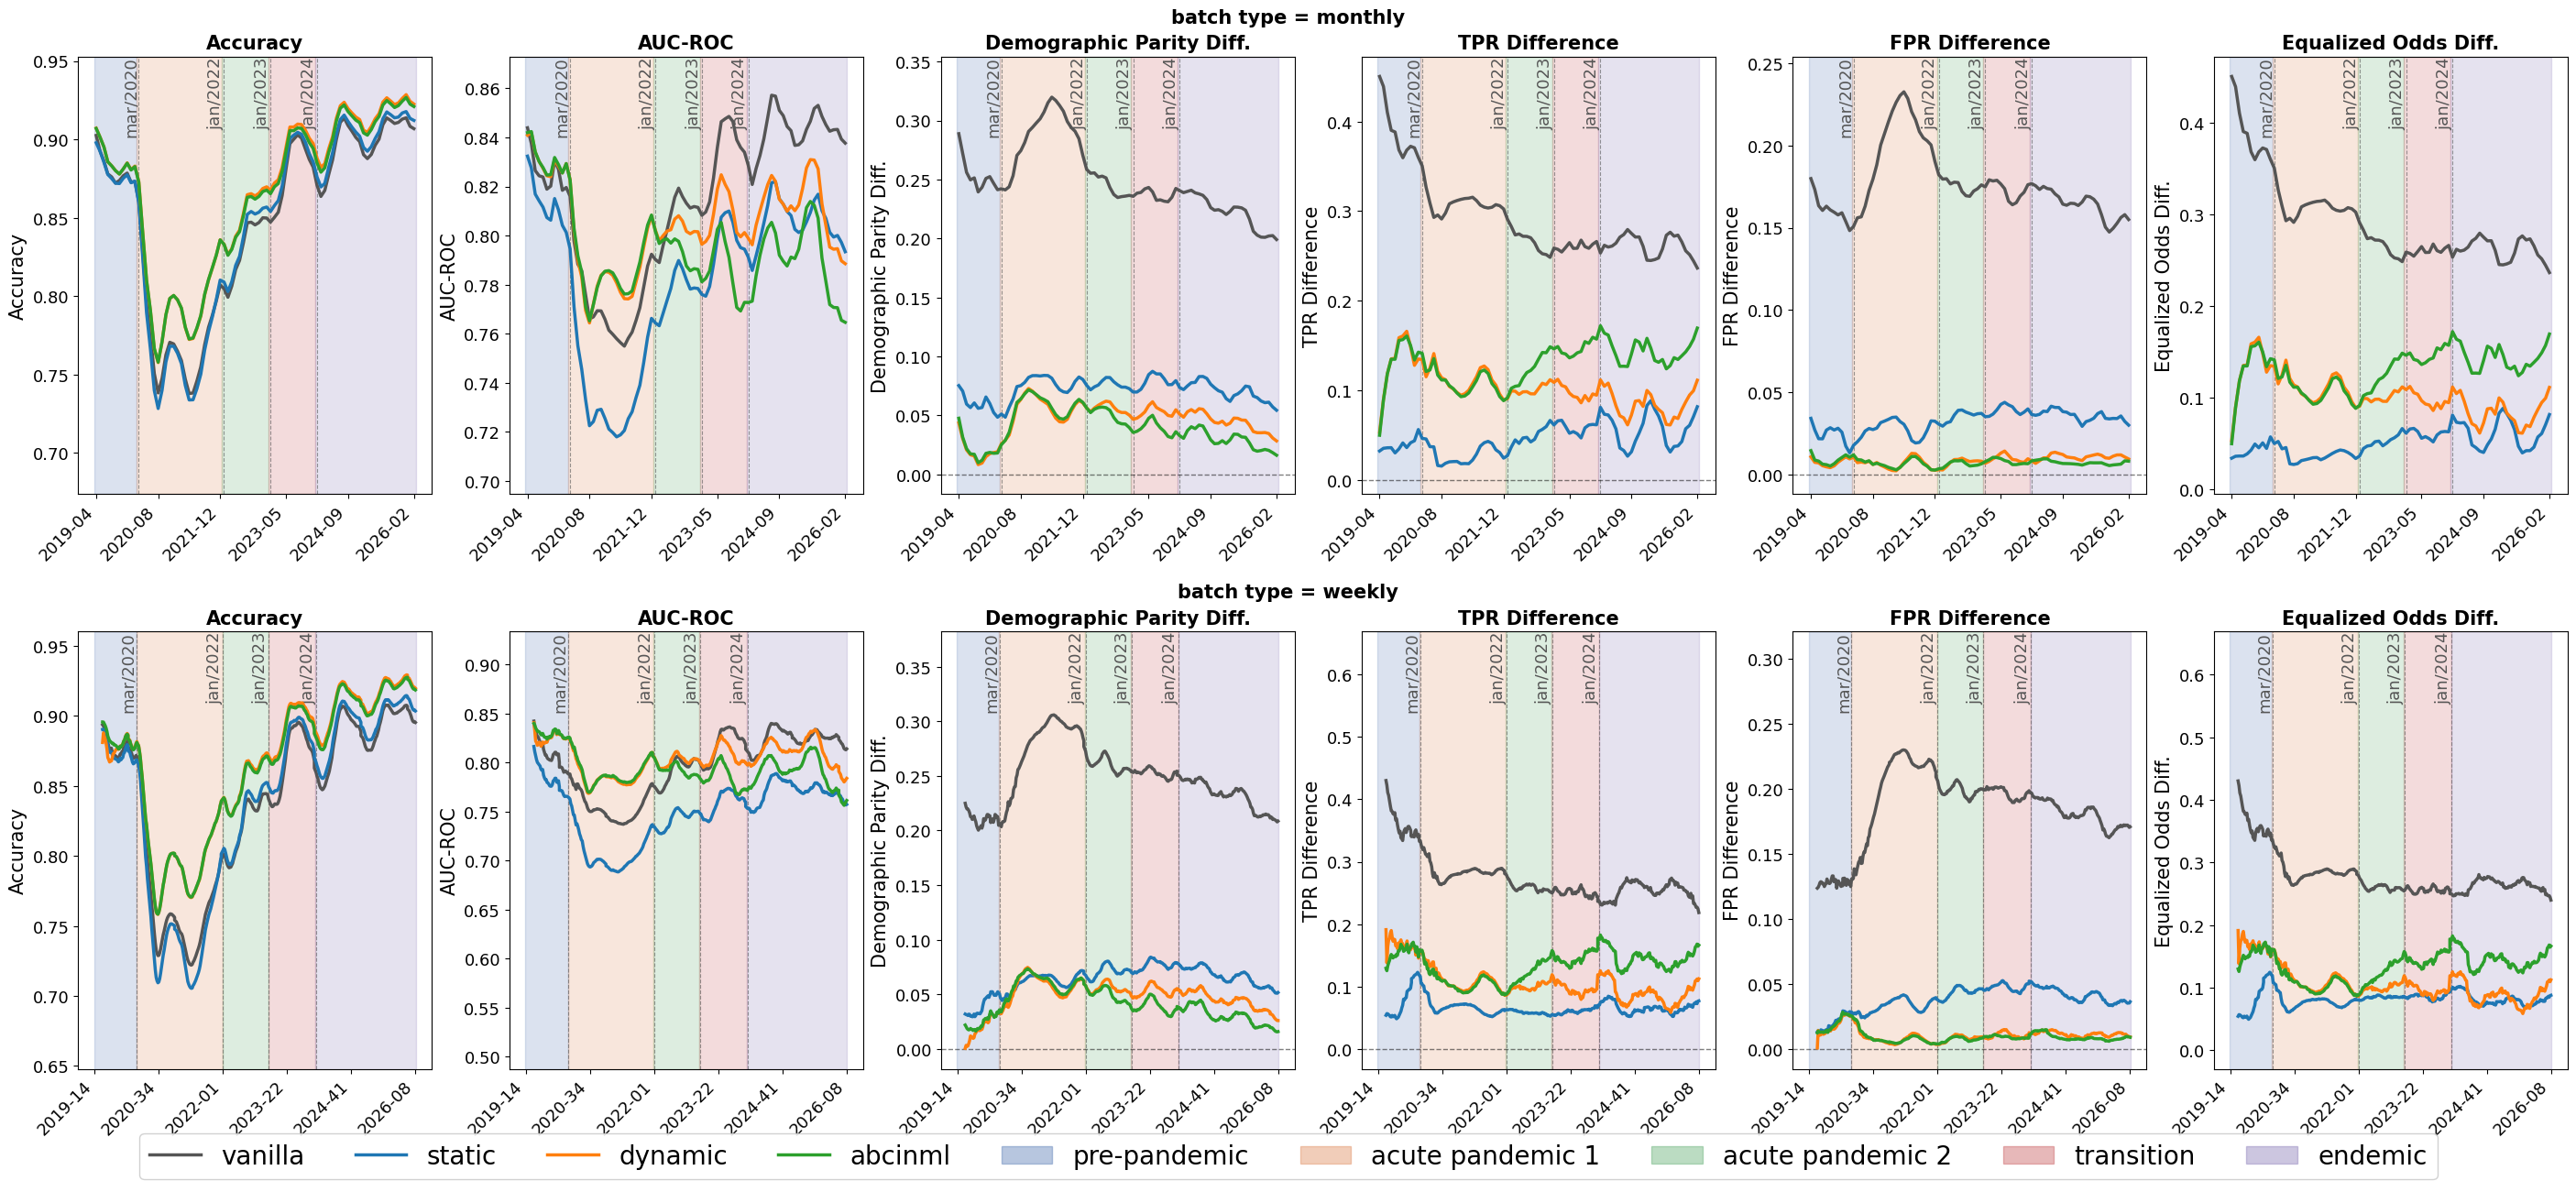

In [4]:
plot_baselines_comparison('logistic_regression')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\comparacao_baselines_xgboost.png


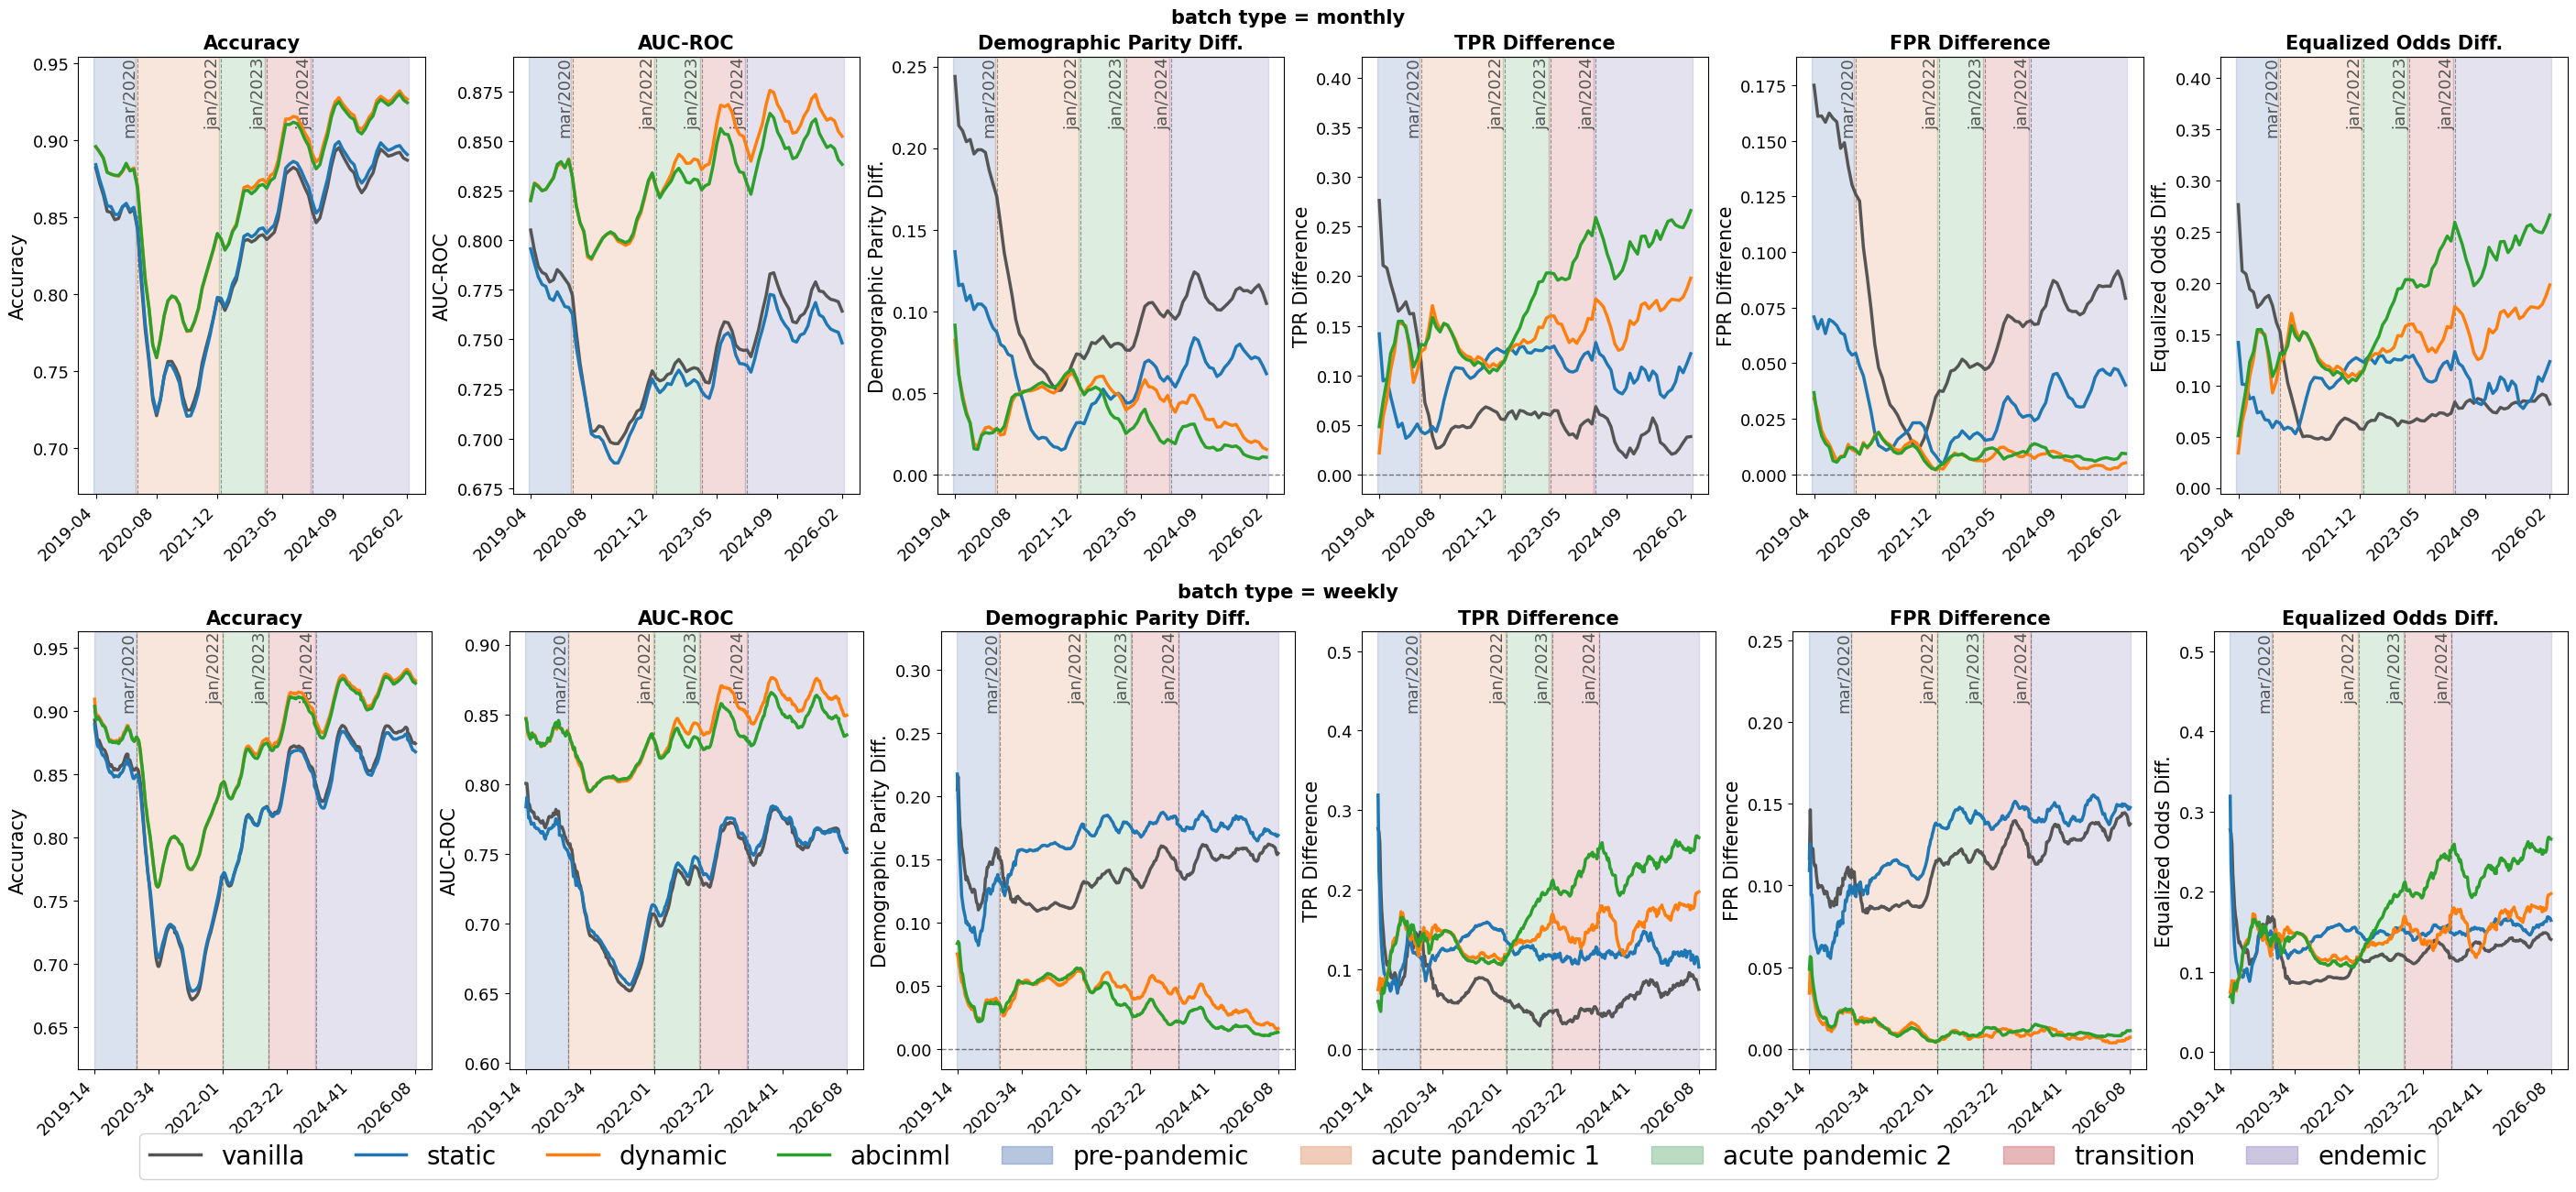

In [5]:
plot_baselines_comparison('xgboost')

## Taxas absolutas por grupo sensível — média por baseline (monthly)

TPR e FPR de cada grupo (S0 privilegiado, S1 sensível) ao longo do tempo, uma fileira por baseline. Média móvel de 10 batches, como no pipeline.

In [6]:
_MA_WINDOW = 10  # padrão do pipeline para monthly
_S0_COLOR = '#ff7f0e'
_S1_COLOR = '#1f77b4'


def plot_absolute_rates(model_name, batch_type='monthly'):
    abs_m = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ].copy()
    abs_m['batch_dt'] = _batch_to_datetime(abs_m['batch'].astype(str).tolist(), batch_type)

    # Média por (baseline, batch): colapsa alphas e janelas de forecast
    abs_mean = abs_m.groupby(['baseline', 'batch', 'batch_dt'], as_index=False)[rate_cols].mean()

    present_baselines = [b for b in _BASELINE_ORDER if b in abs_mean['baseline'].unique()]
    n_rows = len(present_baselines)
    all_batch_labels = sorted(abs_mean['batch'].astype(str).unique())

    tpr_values = pd.concat([abs_mean['tpr_S0'], abs_mean['tpr_S1']])
    tpr_pad = (tpr_values.max() - tpr_values.min()) * 0.05
    tpr_ylim = (tpr_values.min() - tpr_pad, tpr_values.max() + tpr_pad)

    fpr_values = pd.concat([abs_mean['fpr_S0'], abs_mean['fpr_S1']])
    fpr_pad = (fpr_values.max() - fpr_values.min()) * 0.05
    fpr_ylim = (fpr_values.min() - fpr_pad, fpr_values.max() + fpr_pad)

    rate_pairs = [
        ('tpr_S0', 'tpr_S1', 'TPR (True Positive Rate)', tpr_ylim),
        ('fpr_S0', 'fpr_S1', 'FPR (False Positive Rate)', fpr_ylim),
    ]

    fig, axes = plt.subplots(n_rows, 2, figsize=(20, 5 * n_rows), squeeze=False, layout='constrained')

    period_handles = []
    for row, bt in enumerate(present_baselines):
        sub = abs_mean[abs_mean['baseline'] == bt].sort_values('batch_dt').reset_index(drop=True)
        x_str = sub['batch'].astype(str).tolist()
        x_idx = [all_batch_labels.index(b) for b in x_str if b in all_batch_labels]

        for col_idx, (col_s0, col_s1, col_label, ylim) in enumerate(rate_pairs):
            ax = axes[row][col_idx]

            handles = _add_period_spans(ax, all_batch_labels, batch_type)
            if not period_handles:
                period_handles = handles

            ma_s0 = sub[col_s0].rolling(window=_MA_WINDOW, min_periods=1).mean().values
            ma_s1 = sub[col_s1].rolling(window=_MA_WINDOW, min_periods=1).mean().values

            line_s0, = ax.plot(x_idx, ma_s0, color=_S0_COLOR, linewidth=2.0, label='S0 (privileged)')
            line_s1, = ax.plot(x_idx, ma_s1, color=_S1_COLOR, linewidth=2.0, label='S1 (sensitive)')
            ax.fill_between(x_idx, ma_s0, ma_s1, alpha=0.15, color='gray')

            ax.set_title(col_label, fontsize=15, fontweight='bold')
            ax.set_ylabel(col_label, fontsize=15)
            ax.set_ylim(ylim)
            # Legenda interna só com as linhas dos grupos (os períodos ficam na legenda geral)
            ax.legend(handles=[line_s0, line_s1], fontsize=13, framealpha=0.9)
            _apply_bin_xticks(ax, all_batch_labels)
            ax.tick_params(axis='x', labelsize=13)
            ax.tick_params(axis='y', labelsize=13)

        # Rótulo do baseline acima da fileira (coluna direita, como no pipeline)
        axes[row][1].annotate(
            f'Baseline: {bt}',
            xy=(0.5, 1.08),
            xycoords='axes fraction',
            ha='center',
            va='bottom',
            fontsize=15,
            fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f0f0f0', edgecolor='#888888', alpha=0.9),
        )

    # Ajustes pós-plot: alpha das faixas e fonte dos rótulos das vlines —
    # só os textos de data (contêm '/'), preservando as annotations
    for ax in fig.axes:
        for patch in ax.patches:
            patch.set_alpha(0.20)
        for text in ax.texts:
            if '/' in text.get_text():
                text.set_fontsize(13)

    period_labels = [PERIOD_LABELS_EN.get(h.get_label(), h.get_label()) for h in period_handles]
    leg = fig.legend(
        period_handles, period_labels,
        loc='outside lower center', ncol=len(period_handles), fontsize=20, framealpha=0.9,
    )
    for legend_patch in leg.get_patches():
        legend_patch.set_alpha(0.4)

    out_path = fig_dir / f'absolute_rates_by_group_{MODEL_ABBR[model_name]}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight')
    print(f'Figura salva em {out_path}')
    plt.show()

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\absolute_rates_by_group_lr.png


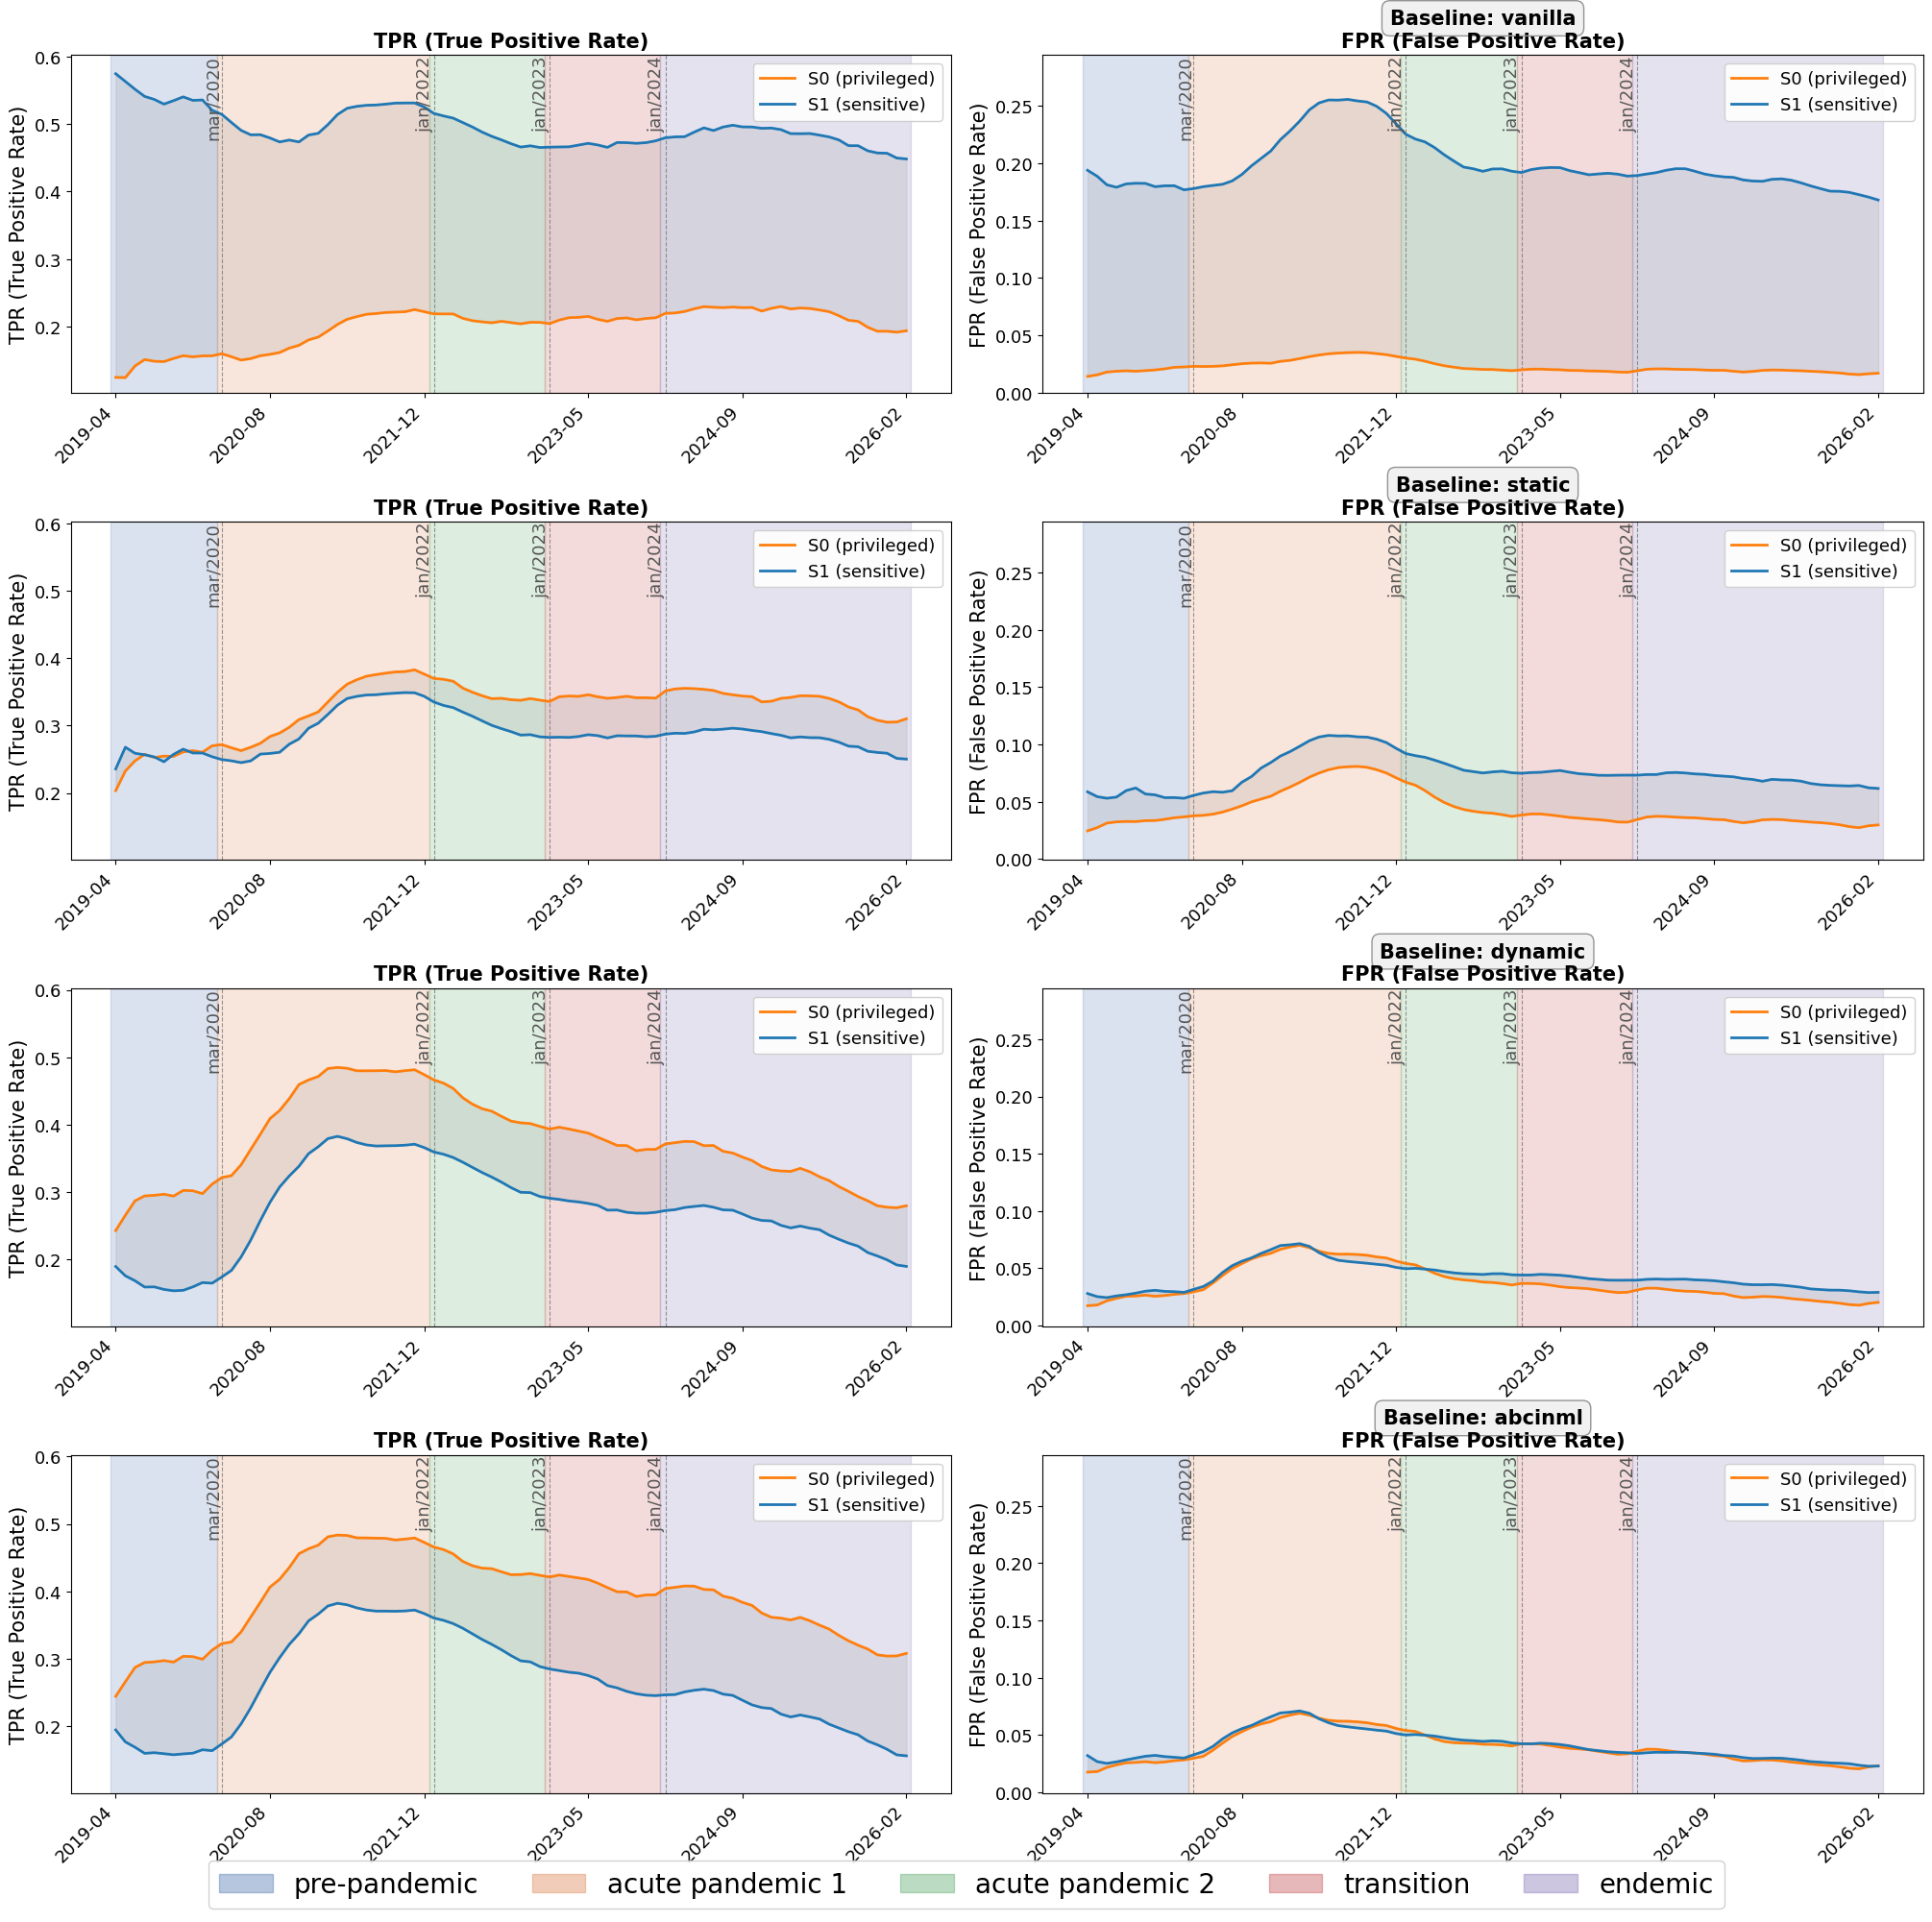

In [7]:
plot_absolute_rates('logistic_regression')

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\absolute_rates_by_group_xgboost.png


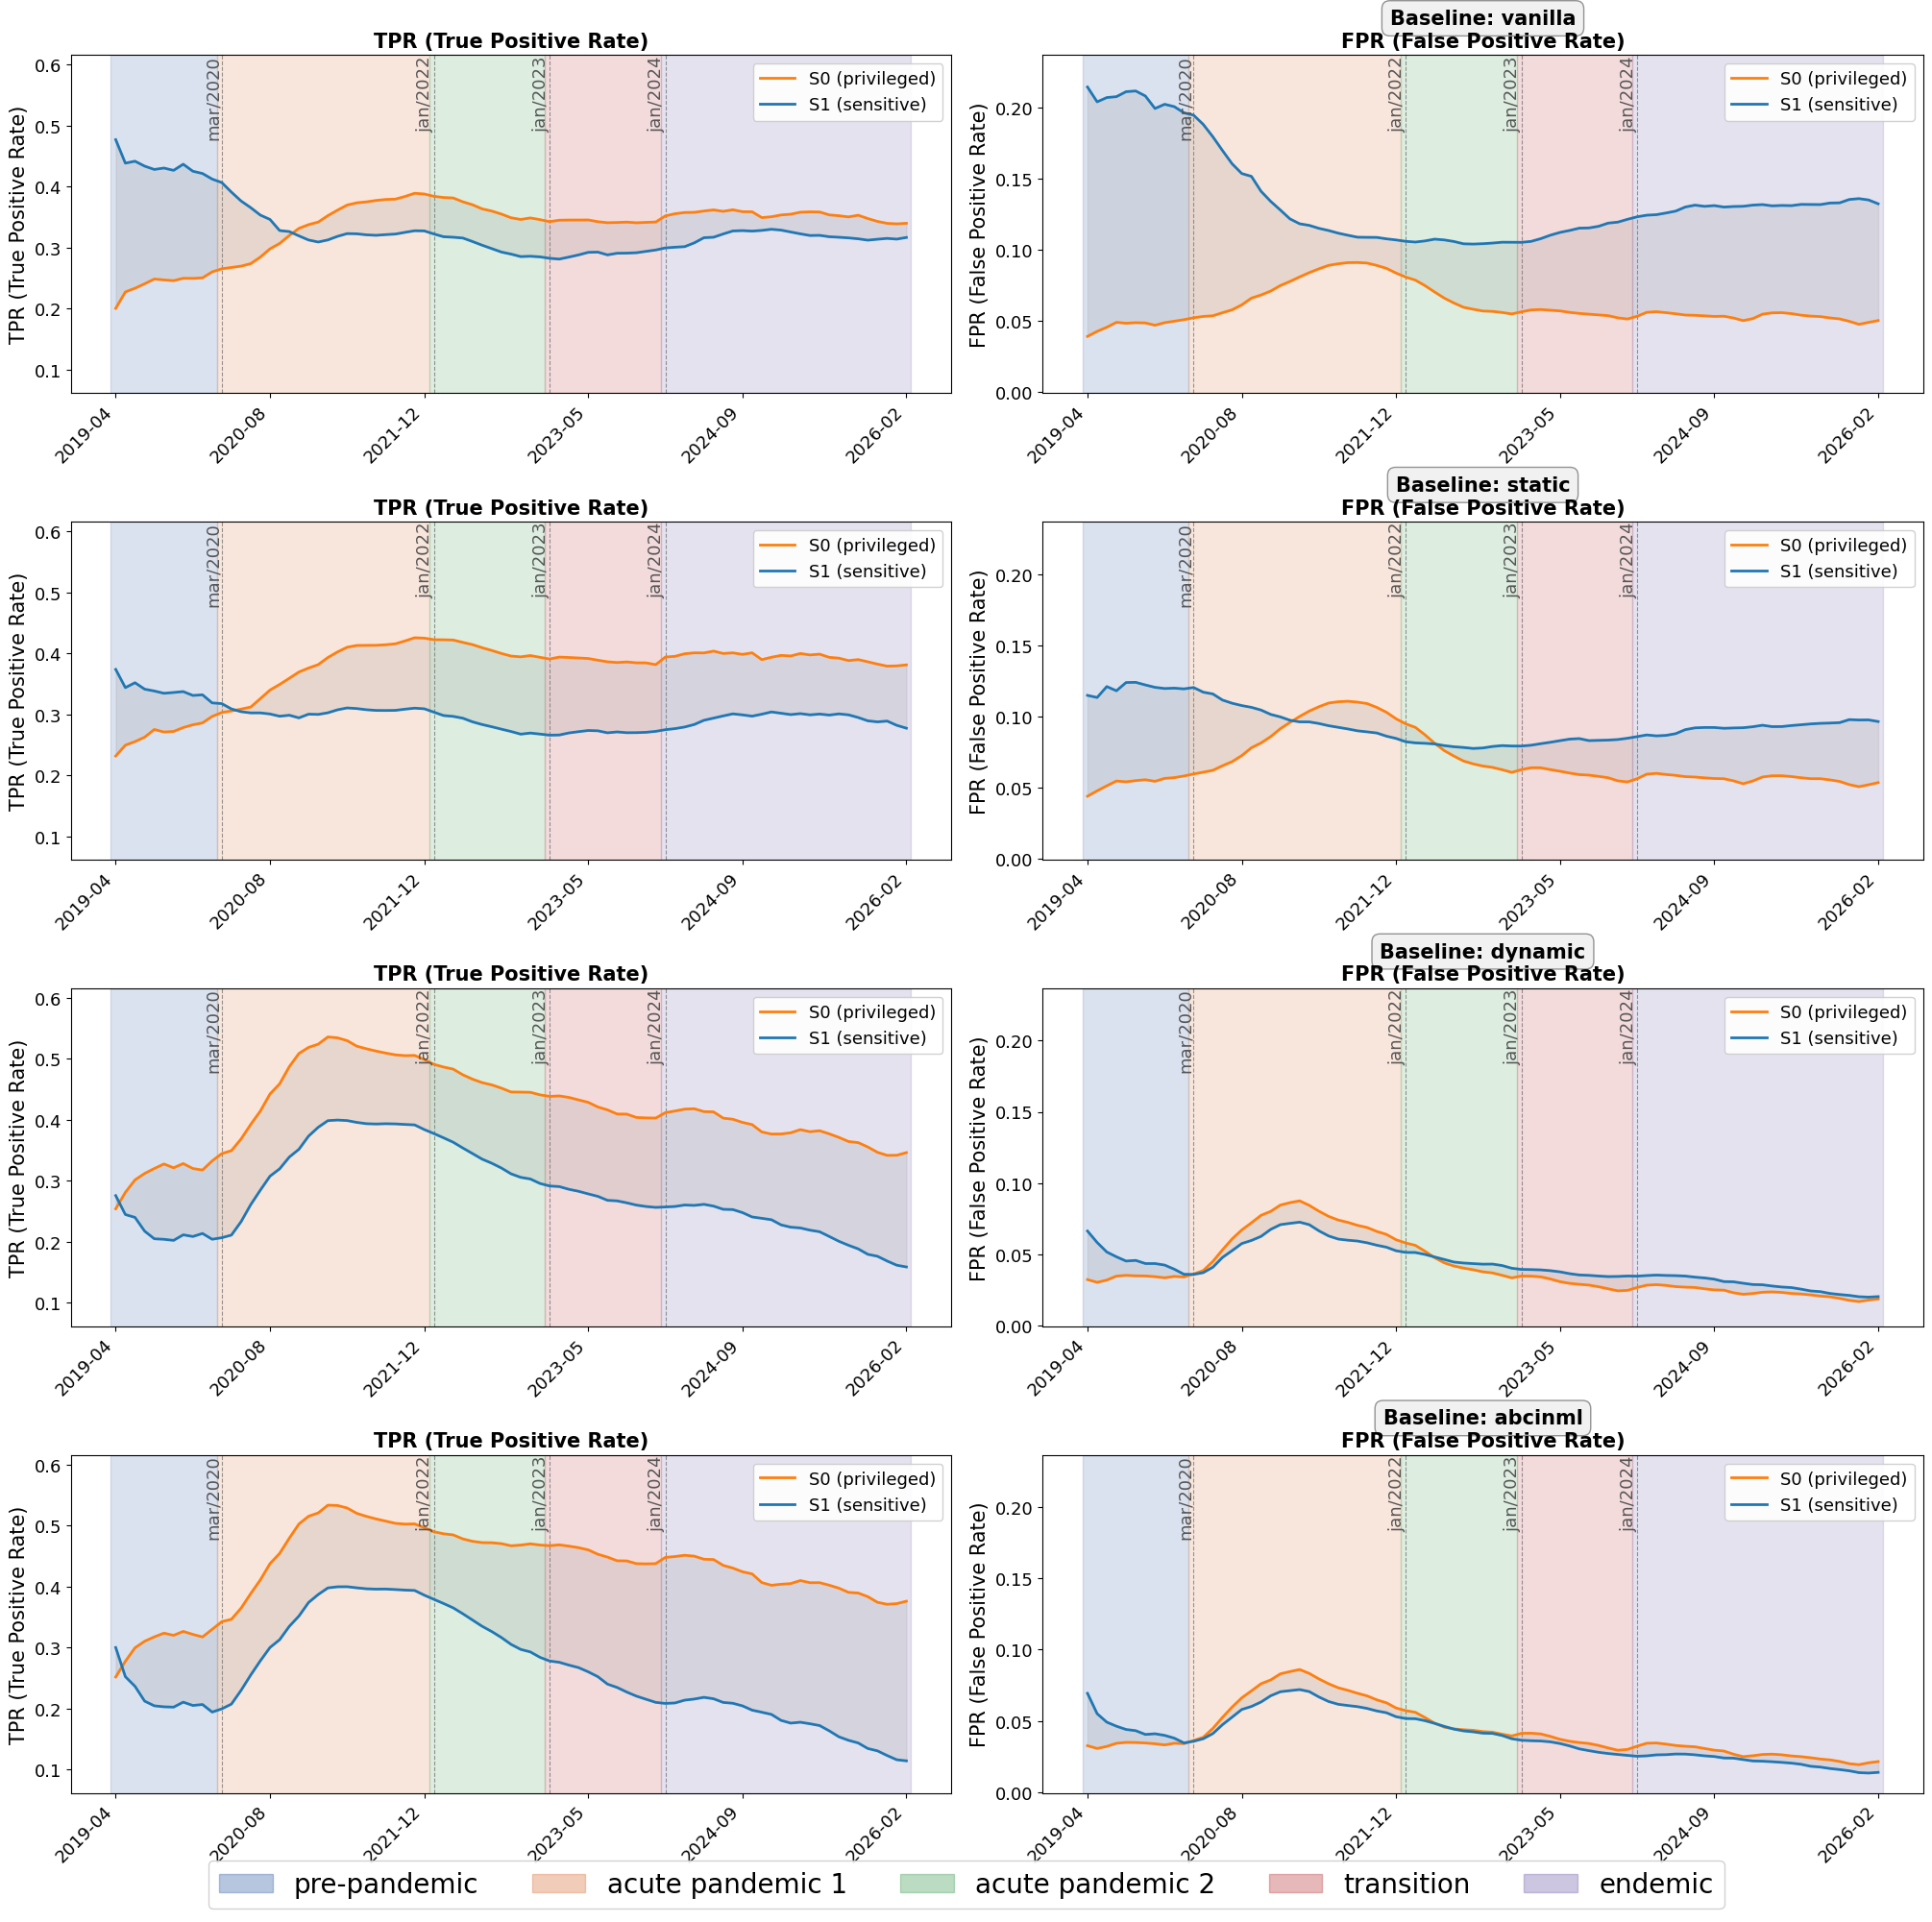

In [8]:
plot_absolute_rates('xgboost')

## Tabela pivot — TPR/FPR médios por baseline e grupo

Versão compacta do gráfico de taxas absolutas. Para cada modelo, uma imagem com duas pivots empilhadas (monthly em cima, weekly embaixo): linhas = baseline, colunas = (TPR/FPR) × (S0/S1), média sobre os batches, em %.

In [9]:
def absolute_rates_pivot(model_name, batch_type, as_percent=True):
    """Pivot: linhas = baseline, colunas = (TPR/FPR) × (S0/S1), média sobre os batches."""
    sub = absolute_df[
        (absolute_df['model_name'] == model_name)
        & (absolute_df['batch_type'] == batch_type)
    ]
    # média por (baseline, batch) e depois média sobre os batches
    per_batch = sub.groupby(['baseline', 'batch'], as_index=False)[rate_cols].mean()
    agg = (
        per_batch.groupby('baseline')[rate_cols].mean()
        .reindex([b for b in _BASELINE_ORDER if b in per_batch['baseline'].unique()])
    )
    piv = pd.DataFrame({
        ('TPR', 'S0 (privileged)'): agg['tpr_S0'],
        ('TPR', 'S1 (sensitive)'): agg['tpr_S1'],
        ('FPR', 'S0 (privileged)'): agg['fpr_S0'],
        ('FPR', 'S1 (sensitive)'): agg['fpr_S1'],
    })
    piv.columns = pd.MultiIndex.from_tuples(piv.columns, names=['Metric', 'Group'])
    piv.index.name = 'Baseline'
    if as_percent:
        piv = piv * 100
    return piv.round(2)


def _draw_pivot_table(ax, piv, subtitle):
    """Desenha uma pivot (colunas MultiIndex 2 níveis) como tabela num eixo, com subtítulo."""
    ax.axis('off')
    ax.set_title(subtitle, fontsize=16, fontweight='bold', pad=12)

    header_metric = [''] + [m for m, _ in piv.columns]           # linha 1: TPR/FPR
    header_group = ['Baseline'] + [g for _, g in piv.columns]    # linha 2: Baseline / S0 / S1
    body = [[idx] + [f'{v:.2f}%' for v in row] for idx, row in zip(piv.index, piv.values)]
    table_data = [header_metric, header_group] + body

    tbl = ax.table(cellText=table_data, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(15)
    tbl.scale(1, 2.2)

    metric_fill = {'TPR': '#dbe9f6', 'FPR': '#fbe3d6'}
    light_gray = '#f5f5f5'
    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:  # linha de métrica: TPR/FPR em bold
            txt = cell.get_text().get_text()
            cell.set_facecolor(metric_fill.get(txt, 'white'))
            if txt:
                cell.get_text().set_fontweight('bold')
            if c == 0:
                cell.set_facecolor('white')
                cell.visible_edges = 'BR'
        elif r == 1:  # cabeçalho: só 'Baseline' em bold; grupos normais, fundo cinza leve
            cell.set_facecolor(light_gray)
            if c == 0:
                cell.get_text().set_fontweight('bold')
        elif c == 0:  # coluna de baseline (valores): fundo cinza leve, sem bold
            cell.set_facecolor(light_gray)


def save_pivot_image(model_name):
    """Uma imagem com duas pivots empilhadas: monthly (cima) e weekly (baixo)."""
    piv_monthly = absolute_rates_pivot(model_name, 'monthly')
    piv_weekly = absolute_rates_pivot(model_name, 'weekly')
    n_rows, n_cols = piv_monthly.shape
    width = 1.9 * (n_cols + 1) + 1.5
    fig, axes = plt.subplots(2, 1, figsize=(width, 2 * (0.5 * (n_rows + 2) + 0.5)))

    _draw_pivot_table(axes[0], piv_monthly, 'batch type = monthly')
    _draw_pivot_table(axes[1], piv_weekly, 'batch type = weekly')

    out_path = fig_dir / f'absolute_rates_pivot_{MODEL_ABBR[model_name]}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight', pad_inches=0.05)
    print(f'Figura salva em {out_path}')
    plt.show()

In [ ]:
def pivot_table_latex(model_name, model_label, label):
    """Pivot TPR/FPR em LaTeX (booktabs), mesmo estilo de temporal_table_latex; blocos monthly e weekly."""
    lines = [
        r'\begin{table}',
        rf'  \caption{{Mean TPR and FPR by Baseline and Group - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrrr}',
        r'    \toprule',
        r'     & \multicolumn{2}{c}{TPR} & \multicolumn{2}{c}{FPR} \\',
        r'    \cmidrule(lr){2-3} \cmidrule(lr){4-5}',
        r'    Baseline & S0 (privileged) & S1 (sensitive) & S0 (privileged) & S1 (sensitive) \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        piv = absolute_rates_pivot(model_name, batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{5}}{{c}}{{\textit{{batch type = {batch_type}}}}} \\',
            r'    \midrule',
        ]
        for baseline, row in zip(piv.index, piv.values):
            lines.append(f'    {baseline} & ' + ' & '.join(rf'{v:.2f}\%' for v in row) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    out_path = fig_dir / f'absolute_rates_pivot_{MODEL_ABBR[model_name]}.tex'
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    print(f'Tabela salva em {out_path}')
    return '\n'.join(lines)

In [ ]:
save_pivot_image('logistic_regression')
print(pivot_table_latex('logistic_regression', 'Logistic Regression', 'tab:absolute-rates-lr'))
absolute_rates_pivot('logistic_regression', 'monthly')

In [ ]:
save_pivot_image('xgboost')
print(pivot_table_latex('xgboost', 'XGBoost', 'tab:absolute-rates-xgboost'))
absolute_rates_pivot('xgboost', 'monthly')

## Tabela — métricas temporais por baseline

Para a seção 4.2 do artigo (LR), no formato da Tabela 3: linhas = baselines, colunas = as três métricas
temporais de `temporal_results_df.csv`, blocos monthly e weekly. As três são calculadas sobre a série de DP Diff.
de cada run, e para todas menor é melhor:
- **Maximum Bias** = max |DP_t|;
- **Temporal Stability** = média de |DP_t − DP_{t−1}|;
- **Maximum Bias Difference** = max |DP_t − DP_{t−1}|.

`abcinml` é a média sobre os 11 alphas, a mesma convenção da Tabela 3.

**Uma janela de forecast por bloco.** A janela define o warm-up, então muda o batch em que o modelo começa a
treinar e o início da série avaliada, inclusive para vanilla/static. No LR weekly, o Maximum Bias do static vai de
10,34% (janela 3) para 18,12% (janela 5). Por isso cada bloco usa uma única janela em que os quatro baselines
existem: **monthly = 3** e **weekly = 5** (no weekly falta o dynamic da janela 3).

In [12]:
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']
TABLE_WINDOW = {'monthly': 3, 'weekly': 5}  # única janela com os 4 baselines em cada batch_type
temporal_table_df = load_filtered('temporal_results_df.csv')


def temporal_metrics_table(model_name, batch_type, as_percent=True):
    """Linhas = baseline, colunas = métricas temporais; abcinml = média sobre os alphas."""
    fw = TABLE_WINDOW[batch_type]
    sub = temporal_table_df[
        (temporal_table_df['model_name'] == model_name)
        & (temporal_table_df['batch_type'] == batch_type)
        & (temporal_table_df['forecast_window'] == fw)
    ]
    missing = [b for b in _BASELINE_ORDER if b not in sub['baseline'].unique()]
    assert not missing, f'{model_name} {batch_type} fw={fw}: faltam {missing}'
    tbl = sub.groupby('baseline')[TEMPORAL_METRICS].mean().reindex(_BASELINE_ORDER)
    tbl.index.name = 'Baseline'
    return (tbl * 100 if as_percent else tbl).round(2)


def temporal_table_latex(model_name, model_label, label):
    """Tabela no estilo da Tabela 3 do artigo (booktabs), com o melhor valor de cada coluna em negrito."""
    header = ' & '.join(['Baseline', 'Max. Bias', 'Temporal Stability', 'Max. Bias Diff.'])
    lines = [
        r'\begin{table}',
        rf'  \caption{{Temporal Fairness Metrics by Baseline - {model_label}.}}',
        rf'  \label{{{label}}}',
        r'  \begin{tabular}{lrrr}',
        r'    \toprule',
        rf'    {header} \\',
    ]
    for batch_type in ('monthly', 'weekly'):
        tbl = temporal_metrics_table(model_name, batch_type)
        lines += [
            r'    \midrule',
            rf'    \multicolumn{{4}}{{c}}{{\textit{{batch type = {batch_type}, forecast window = {TABLE_WINDOW[batch_type]}}}}} \\',
            r'    \midrule',
        ]
        for baseline, row in tbl.iterrows():
            cells = [
                rf'\textbf{{{v:.2f}\%}}' if v == tbl[col].min() else rf'{v:.2f}\%'
                for col, v in row.items()
            ]
            lines.append(f'    {baseline} & ' + ' & '.join(cells) + r' \\')
    lines += [r'    \bottomrule', r'  \end{tabular}', r'\end{table}']
    out_path = fig_dir / f'temporal_metrics_{MODEL_ABBR[model_name]}.tex'
    out_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
    print(f'Tabela salva em {out_path}')
    return '\n'.join(lines)


pd.concat({bt: temporal_metrics_table('logistic_regression', bt) for bt in ('monthly', 'weekly')})

Maximum Bias  Temporal Stability  Maximum Bias Difference
        Baseline                                                           
monthly vanilla          33.73                1.29                     7.66
        static           10.10                1.14                     6.19
        dynamic           8.25                0.99                     4.78
        abcinml           9.13                1.17                     5.00
weekly  vanilla          36.42                1.95                    24.94
        static           18.12                1.55                    10.99
        dynamic          10.97                1.13                     8.14
        abcinml           9.95                1.12                     8.65

In [13]:
print(temporal_table_latex('logistic_regression', 'Logistic Regression', 'tab:temporal-lr'))

Tabela salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\temporal_metrics_lr.tex
\begin{table}
  \caption{Temporal Fairness Metrics by Baseline - Logistic Regression.}
  \label{tab:temporal-lr}
  \begin{tabular}{lrrr}
    \toprule
    Baseline & Max. Bias & Temporal Stability & Max. Bias Diff. \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = monthly, forecast window = 3}} \\
    \midrule
    vanilla & 33.73\% & 1.29\% & 7.66\% \\
    static & 10.10\% & 1.14\% & 6.19\% \\
    dynamic & \textbf{8.25\%} & \textbf{0.99\%} & \textbf{4.78\%} \\
    abcinml & 9.13\% & 1.17\% & 5.00\% \\
    \midrule
    \multicolumn{4}{c}{\textit{batch type = weekly, forecast window = 5}} \\
    \midrule
    vanilla & 36.42\% & 1.95\% & 24.94\% \\
    static & 18.12\% & 1.55\% & 10.99\% \\
    dynamic & 10.97\% & 1.13\% & \textbf{8.14\%} \\
    abcinml & \textbf{9.95\%} & \textbf{1.12\%} & 8.65\% \\
    \bottomrule
  \end{tabular}
\end{table}


## Fronteira accuracy × métrica — LR vs. XGBoost vs. Random Forest (variando alpha)

Cada ponto é um valor de `alpha` do `abcinml`: média de accuracy (eixo x) e da métrica (eixo y) sobre todos os batches (e janelas de forecast) daquele alpha. Uma figura por `batch_type` e por métrica do eixo y (DP, TPR e FPR Diff., AUC). As pontas α = 0 (antecipação pura) e α = 1 (equivalente ao dynamic) são rotuladas.

As setas ao lado dos eixos apontam para onde a métrica é melhor: maior para accuracy/AUC; mais perto de zero para as diferenças entre grupos.

**Random Forest (resultados parciais):** por enquanto só tem `forecast_window = 3`, enquanto LR e XGBoost fazem a média de 3, 5 e 10. Restringir LR/XGBoost a `fw = 3` move seus pontos no máximo ~0,15 pp, então a comparação vale, mas os pontos do RF ainda vão mudar quando as janelas 5 e 10 rodarem.

In [14]:
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.textpath import TextPath

# RF entra só nas fronteiras; MODELS (LR/XGBoost) continua valendo para os gráficos anteriores
FRONTIER_MODELS = MODELS + ['random_forest']
frontier_df = load_filtered('assessment_all_baselines.csv', FRONTIER_MODELS)

MODEL_COLORS = {'logistic_regression': '#1f77b4', 'xgboost': '#d62728', 'random_forest': '#2ca02c'}
MODEL_MARKERS = {'logistic_regression': 'o', 'xgboost': 's', 'random_forest': '^'}
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'xgboost': 'XGBoost', 'random_forest': 'Random Forest'}
LABEL_LANES = {'logistic_regression': (-9, 'right'), 'random_forest': (9, 'left'), 'xgboost': (62, 'left')}
METRIC_LABELS = dict(_SNAPSHOT_METRICS)
HIGHER_IS_BETTER = {'acc', 'auc'}  # demais métricas: diferenças entre grupos, melhor perto de 0


def frontier_points(model_name, batch_type, metric):
    """Média de accuracy e da métrica (em %) por alpha, só abcinml."""
    abc = frontier_df[
        (frontier_df['model_name'] == model_name)
        & (frontier_df['batch_type'] == batch_type)
        & (frontier_df['baseline'] == 'abcinml')
    ]
    return abc.groupby('alpha')[['acc', metric]].mean().sort_index() * 100


def _underline(ax, xy, dx, dy, ha, text, color, fontsize=12):
    """Sublinha, na cor do modelo, um rótulo posicionado a (dx, dy) pontos do ponto xy (em dados)."""
    width = TextPath((0, 0), text, size=fontsize).get_extents().width  # em pontos
    x0, x1 = (dx - width, dx) if ha == 'right' else (dx, dx + width)
    # Coordenadas em pontos relativas ao ponto de dados: acompanha o layout final do savefig
    trans = (
        mtransforms.Affine2D().scale(1 / 72) + ax.figure.dpi_scale_trans
        + mtransforms.ScaledTranslation(*xy, ax.transData)
    )
    ax.add_artist(Line2D([x0, x1], [dy - 8, dy - 8], transform=trans, color=color, linewidth=2.2))


def _better_arrow(ax, axis, positive):
    """Seta fora do eixo apontando para onde a métrica melhora (positive = sentido crescente)."""
    style = dict(arrowstyle='-|>', color='#555555', lw=1.8, mutation_scale=16)
    text = dict(fontsize=12, color='#555555', annotation_clip=False)
    if axis == 'x':  # na linha do rótulo do eixo x, à direita
        tail, head = (0.80, -0.115), (0.97, -0.115)
        if not positive:
            tail, head = head, tail
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(min(tail[0], head[0]) - 0.01, -0.115), xycoords='axes fraction',
                    ha='right', va='center', **text)
    else:  # à direita do eixo y, na ponta para onde a métrica melhora
        tail, head = ((1.025, 0.62), (1.025, 0.98)) if positive else ((1.025, 0.38), (1.025, 0.02))
        ax.annotate('', xy=head, xytext=tail, xycoords='axes fraction', arrowprops=style, annotation_clip=False)
        ax.annotate('better', xy=(1.045, (tail[1] + head[1]) / 2), xycoords='axes fraction',
                    rotation=90, ha='left', va='center', **text)


def _draw_frontier(ax, batch_type, metric='dp', points_fn=None):
    y_values = []
    for model in FRONTIER_MODELS:
        pts = (points_fn or frontier_points)(model, batch_type, metric)
        y_values.extend(pts[metric])
        ax.scatter(
            pts['acc'], pts[metric],
            color=MODEL_COLORS[model], marker=MODEL_MARKERS[model], s=60,
            edgecolor='white', linewidth=1.0, zorder=3, label=MODEL_LABELS[model],
        )
        # Rótulos só nas pontas: indicam o sentido de alpha ao longo da fronteira.
        # Cada modelo vira uma coluna quase vertical (LR < XGBoost < RF em accuracy). Uma faixa de
        # rótulos por modelo: LR à esquerda, RF logo à direita dos seus pontos e XGBoost numa faixa
        # mais à direita, para não cair sobre os pontos nem sobre os rótulos do RF.
        dx, ha = LABEL_LANES[model]
        a0, a1 = pts.index.min(), pts.index.max()
        # Afasta verticalmente os dois rótulos do mesmo modelo (evita encostarem quando próximos)
        away = 6 if pts.loc[a0, metric] >= pts.loc[a1, metric] else -6
        for alpha, dy in ((a0, away), (a1, -away)):
            text = f'α = {alpha:g}'
            xy = (pts.loc[alpha, 'acc'], pts.loc[alpha, metric])
            ax.annotate(
                text, xy, xytext=(dx, dy), textcoords='offset points', ha=ha, va='center',
                fontsize=12, color='#333333',
            )
            _underline(ax, xy, dx, dy, ha, text, MODEL_COLORS[model])

    ax.margins(y=0.08)  # espaço para os rótulos das pontas
    ax.set_xlim(80, 90)  # escala fixa de accuracy, comum a todas as fronteiras
    label = METRIC_LABELS.get(metric, metric)
    ax.set_xlabel('Accuracy (%)', fontsize=15)
    ax.set_ylabel(f'{label} (%)', fontsize=15)
    ax.set_title(
        f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF ({batch_type} batches)',
        fontsize=15, fontweight='bold',
    )
    ax.tick_params(axis='both', labelsize=13)
    ax.grid(color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=13, framealpha=0.9, loc='best')

    _better_arrow(ax, 'x', positive=True)
    # Diferenças entre grupos melhoram em direção a zero: o sentido depende do sinal dos valores
    y_positive = metric in HIGHER_IS_BETTER or pd.Series(y_values).median() < 0
    _better_arrow(ax, 'y', positive=y_positive)


def _save_frontier(fig, metric, suffix):
    slug = metric.lower().replace(' ', '_')
    out_path = fig_dir / f'fronteira_acc_{slug}_{suffix}.png'
    fig.savefig(out_path, dpi=120, bbox_inches='tight')
    print(f'Figura salva em {out_path}')
    plt.show()


def plot_frontier(batch_type, metric='dp', points_fn=None):
    fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
    _draw_frontier(ax, batch_type, metric, points_fn)
    _save_frontier(fig, metric, batch_type)


def plot_frontier_pair(metric='dp', points_fn=None):
    """Os gráficos monthly e weekly da métrica lado a lado, como subplots de uma só figura."""
    fig, axes = plt.subplots(1, 2, figsize=(21, 6), layout='constrained')
    for ax, batch_type in zip(axes, ('monthly', 'weekly')):
        _draw_frontier(ax, batch_type, metric, points_fn)
        ax.set_title(f'{batch_type} batches', fontsize=15, fontweight='bold')  # parte comum vai no suptitle
    label = METRIC_LABELS.get(metric, metric)
    fig.suptitle(f'Accuracy vs. {label} across α — LR vs. XGBoost vs. RF', fontsize=17, fontweight='bold')
    _save_frontier(fig, metric, 'monthly_weekly')


pd.concat({m: frontier_points(m, 'monthly', 'dp') for m in FRONTIER_MODELS}, axis=1).round(2)

logistic_regression       xgboost       random_forest      
                      acc    dp     acc    dp           acc    dp
alpha                                                            
0.0                 86.49  3.22   86.63  2.89         86.71  2.05
0.1                 86.51  3.35   86.67  2.87         86.74  2.07
0.2                 86.54  3.50   86.70  2.86         86.76  2.08
0.3                 86.56  3.65   86.74  2.92         86.78  2.16
0.4                 86.59  3.81   86.77  3.01         86.80  2.20
0.5                 86.61  3.97   86.81  3.14         86.83  2.29
0.6                 86.64  4.13   86.84  3.31         86.85  2.32
0.7                 86.66  4.29   86.87  3.50         86.87  2.41
0.8                 86.68  4.45   86.90  3.67         86.88  2.50
0.9                 86.70  4.59   86.93  3.87         86.90  2.58
1.0                 86.73  4.75   86.98  4.14         86.92  2.74

### Demographic Parity Diff.

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_dp_monthly.png


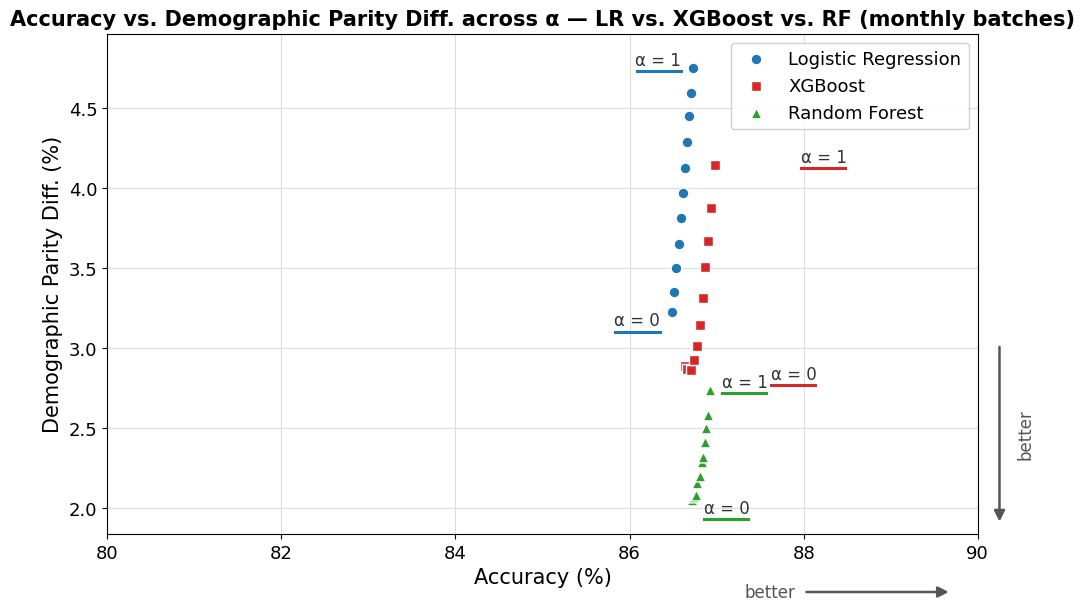

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_dp_weekly.png


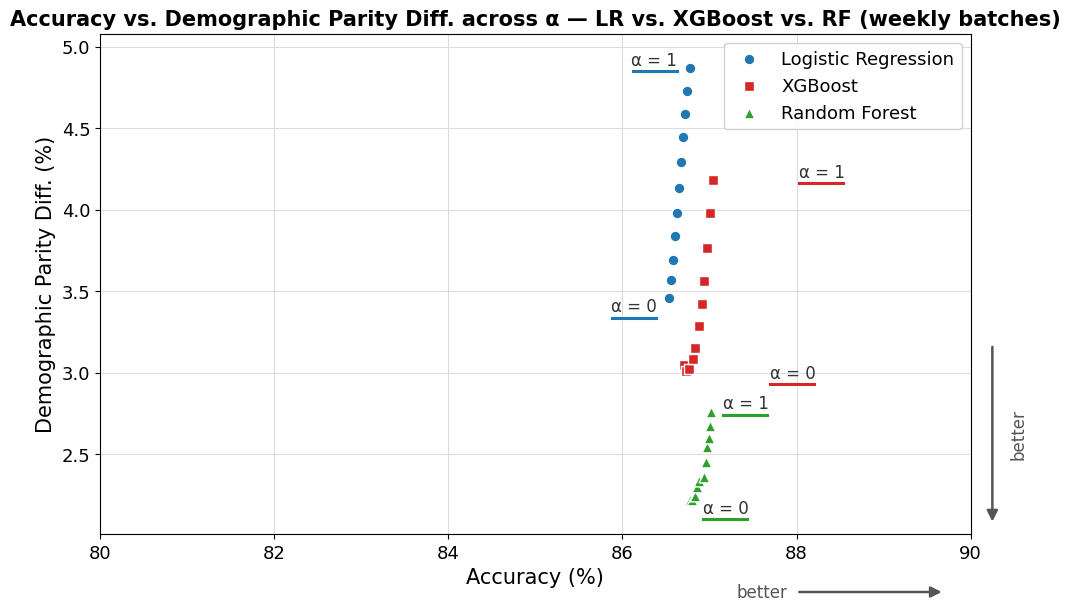

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_dp_monthly_weekly.png


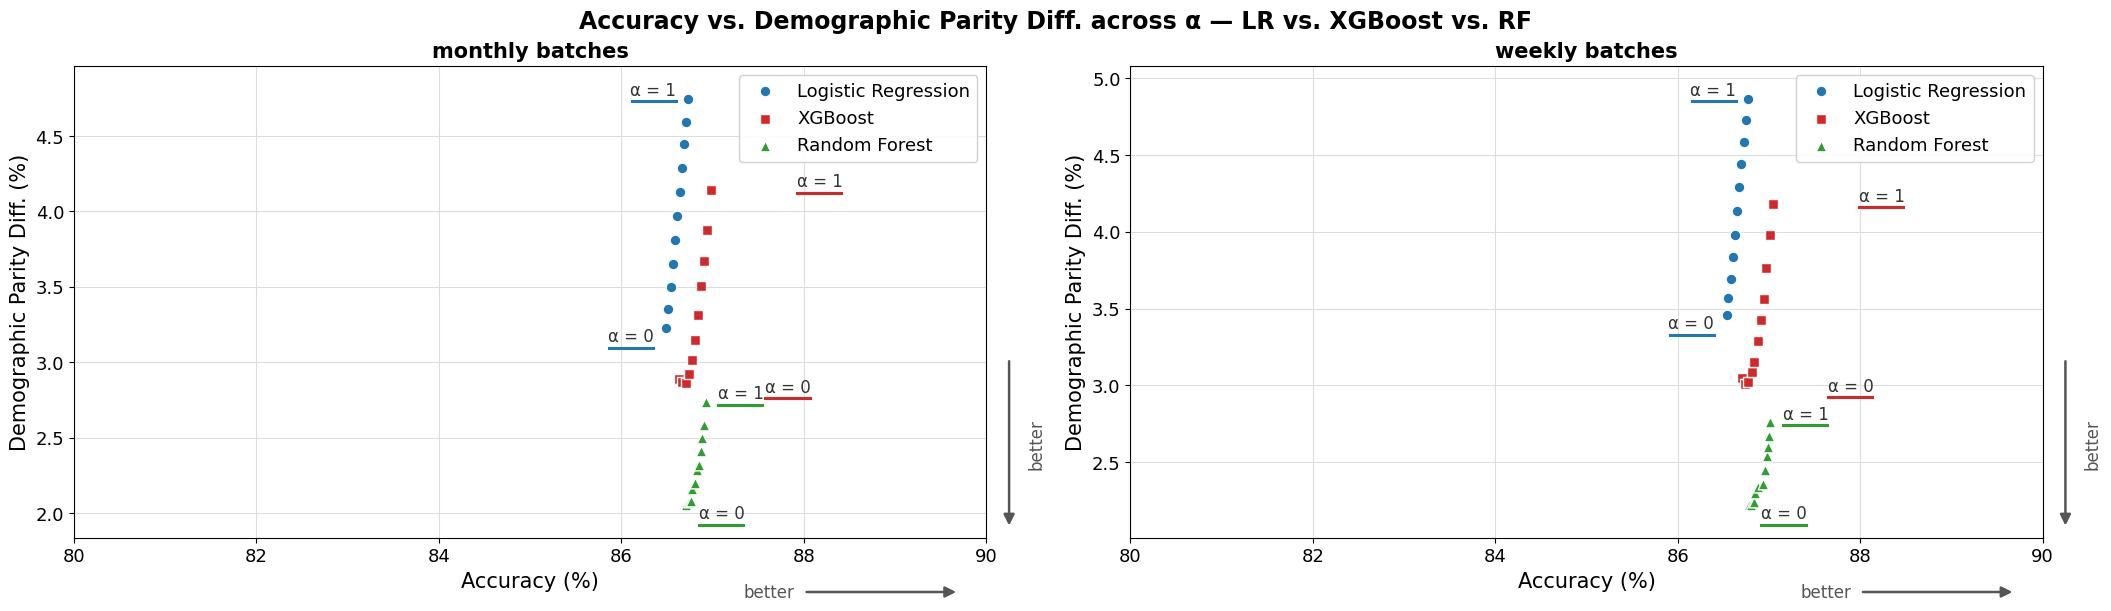

In [15]:
plot_frontier('monthly', 'dp')
plot_frontier('weekly', 'dp')
plot_frontier_pair('dp')

### TPR Difference

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_tpr_diff_monthly.png


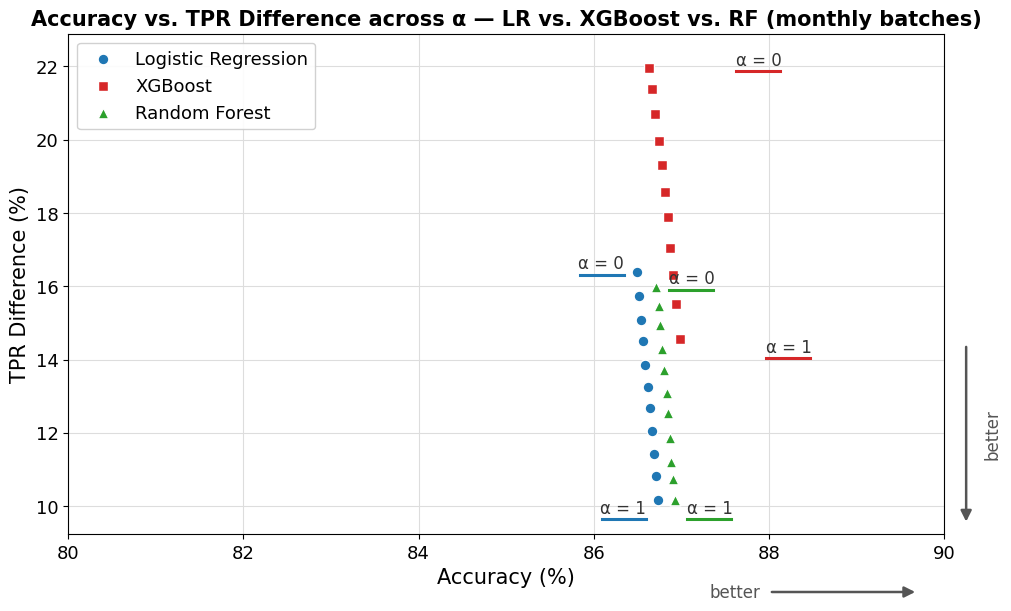

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_tpr_diff_weekly.png


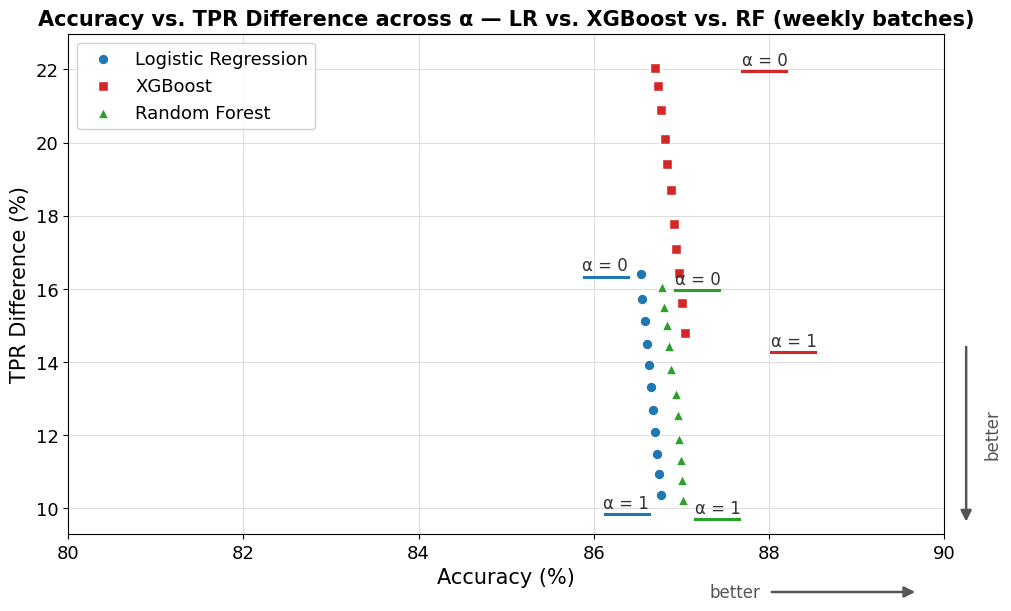

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_tpr_diff_monthly_weekly.png


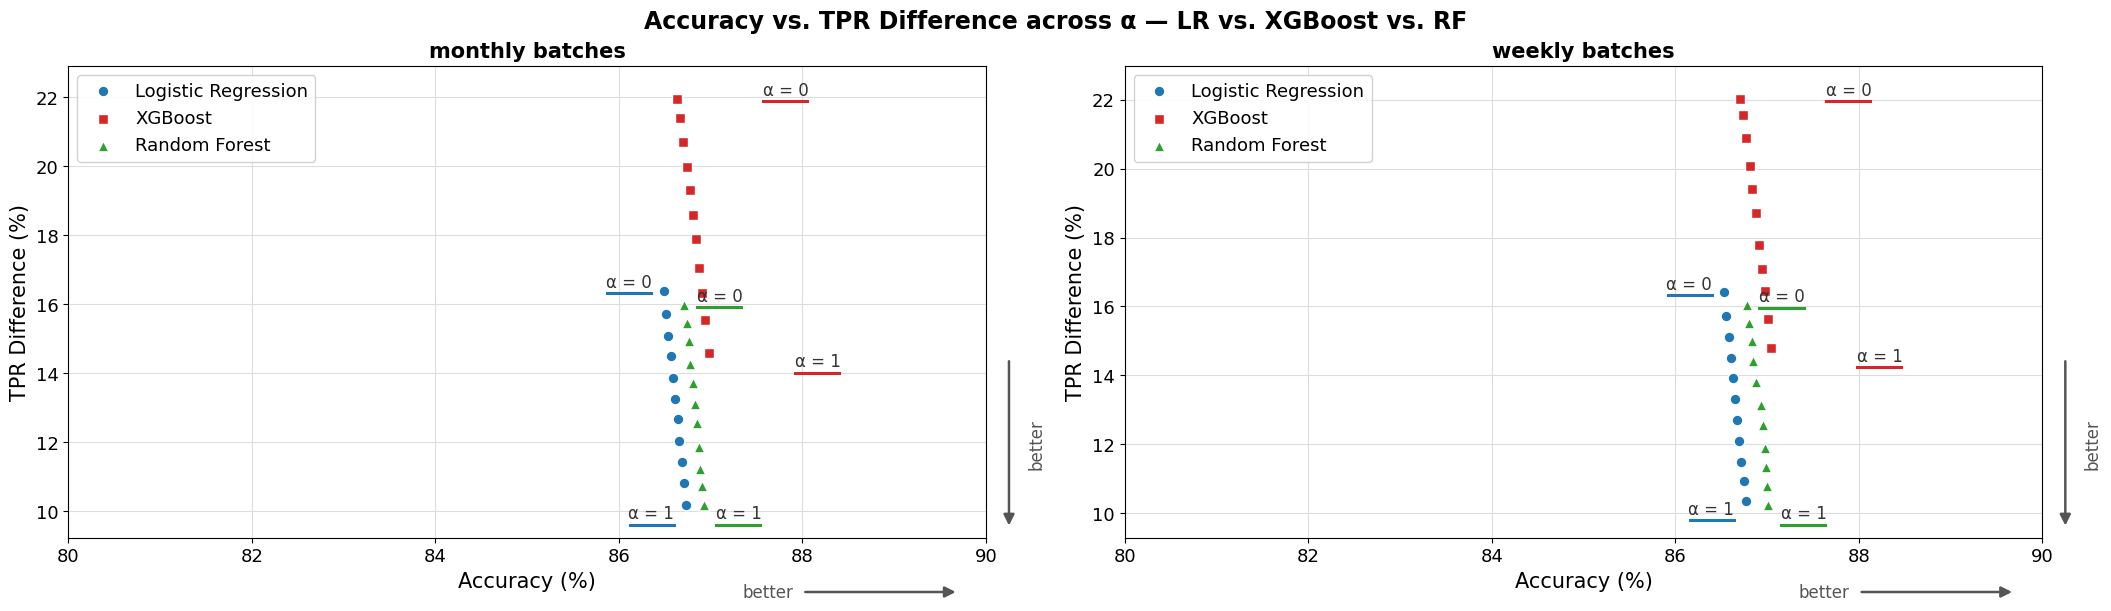

In [16]:
plot_frontier('monthly', 'tpr_diff')
plot_frontier('weekly', 'tpr_diff')
plot_frontier_pair('tpr_diff')

### FPR Difference

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_fpr_diff_monthly.png


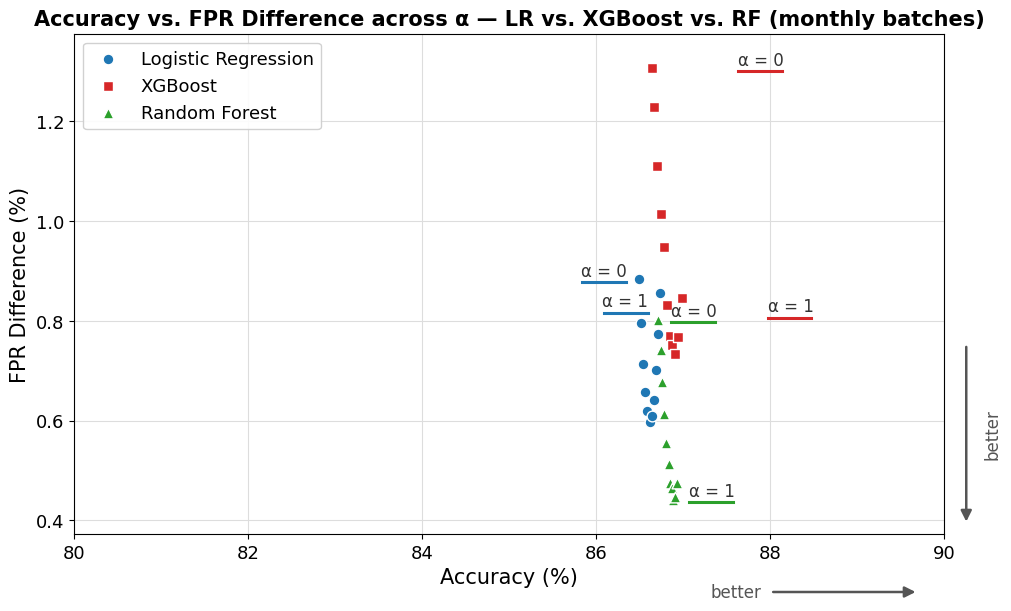

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_fpr_diff_weekly.png


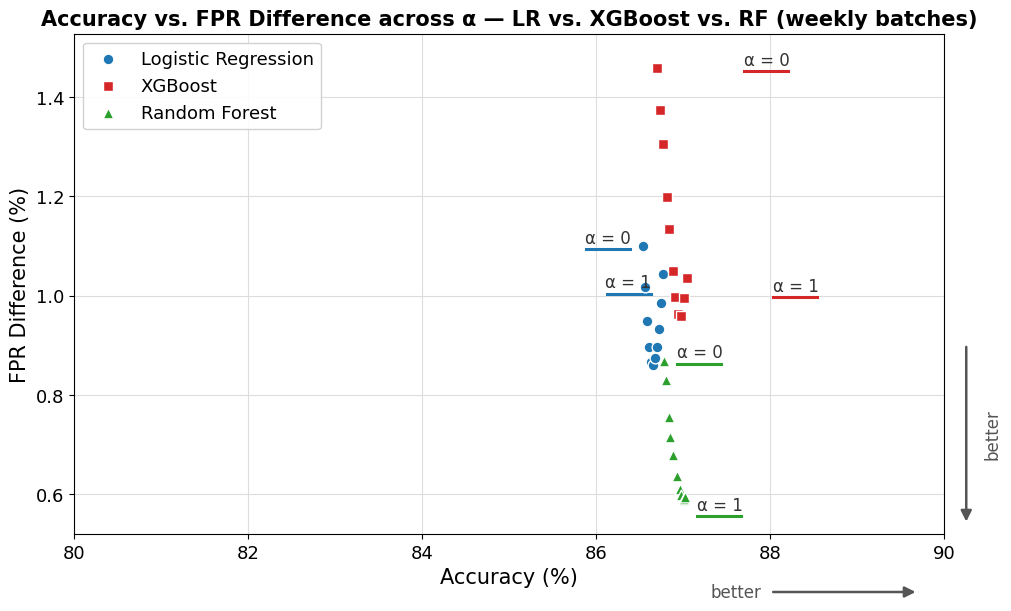

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_fpr_diff_monthly_weekly.png


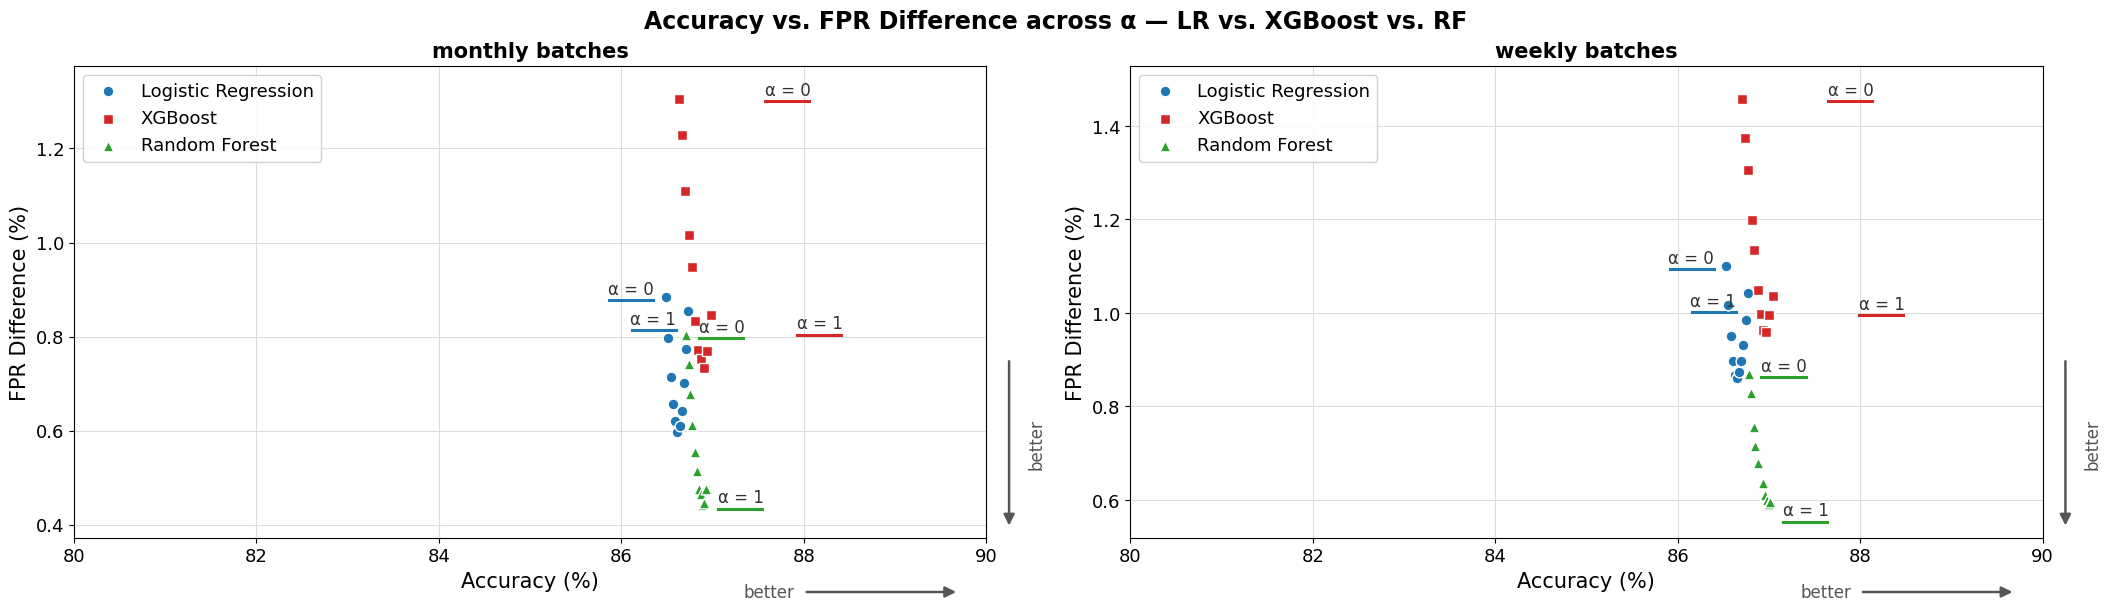

In [17]:
plot_frontier('monthly', 'fpr_diff')
plot_frontier('weekly', 'fpr_diff')
plot_frontier_pair('fpr_diff')

### AUC-ROC

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_auc_monthly.png


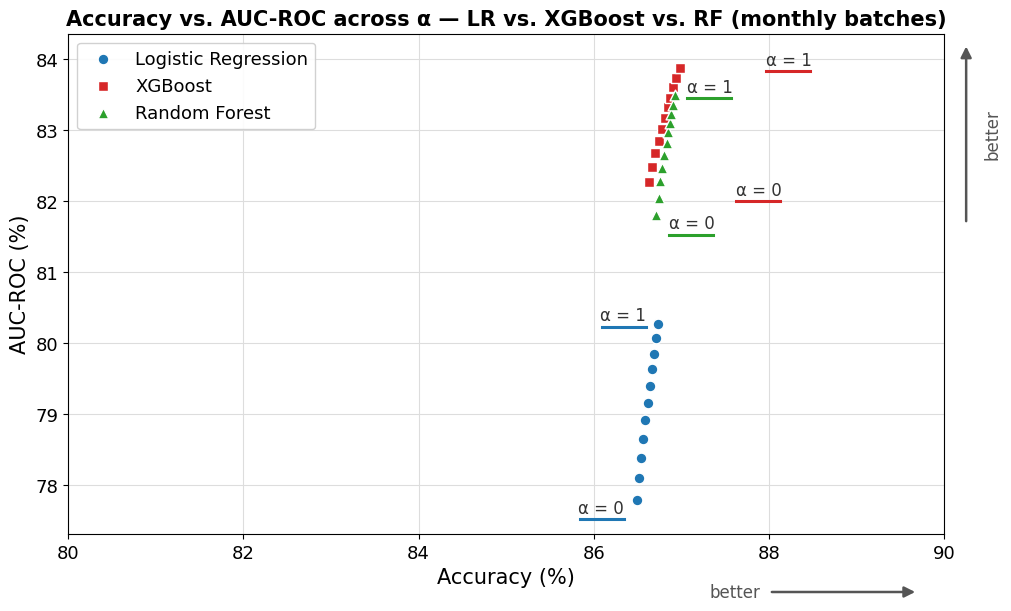

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_auc_weekly.png


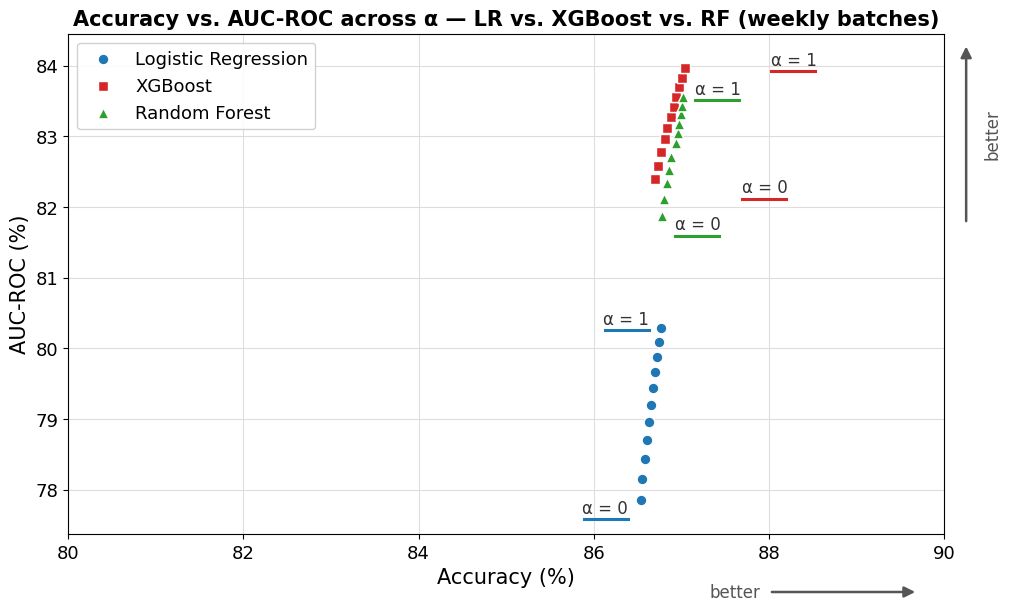

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_auc_monthly_weekly.png


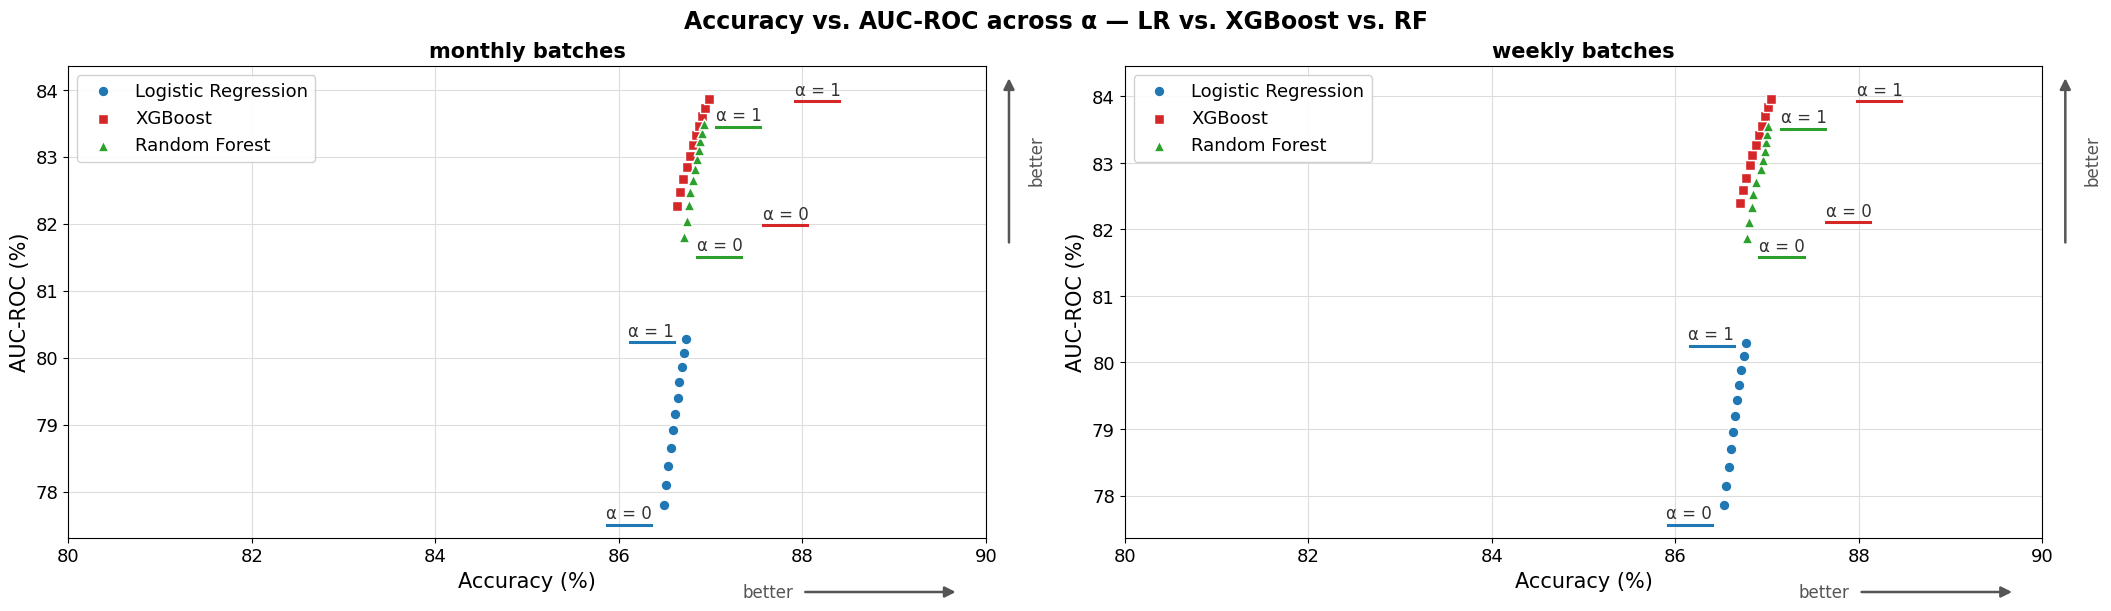

In [18]:
plot_frontier('monthly', 'auc')
plot_frontier('weekly', 'auc')
plot_frontier_pair('auc')

## Fronteira accuracy × métricas temporais — LR vs. XGBoost vs. Random Forest (variando alpha)

Mesmos filtros e visual das fronteiras acima, com o eixo y vindo de `temporal_results_df.csv`. As três métricas são calculadas sobre a série de DP Diff. de cada run (`compute_temporal_metrics`), e para todas menor é melhor:
- **Maximum Bias**: maior |DP| ao longo dos batches;
- **Temporal Stability**: variação média de DP entre batches consecutivos;
- **Maximum Bias Difference**: maior salto de DP entre batches consecutivos.

Cada ponto é um `alpha` do `abcinml`: accuracy média sobre os batches e métrica temporal média sobre as runs daquele alpha (uma por janela de forecast).

**Random Forest (resultados parciais):** por enquanto só tem `forecast_window = 3`, enquanto LR e XGBoost fazem a média de 3, 5 e 10. Restringir LR/XGBoost a `fw = 3` move seus pontos no máximo ~0,15 pp, então a comparação vale, mas os pontos do RF ainda vão mudar quando as janelas 5 e 10 rodarem.

In [19]:
temporal_df = load_filtered('temporal_results_df.csv', FRONTIER_MODELS)
TEMPORAL_METRICS = ['Maximum Bias', 'Temporal Stability', 'Maximum Bias Difference']


def temporal_frontier_points(model_name, batch_type, metric):
    """Accuracy média (assessment) e métrica temporal média (temporal_results), em %, por alpha."""
    acc = frontier_points(model_name, batch_type, 'auc')['acc']
    tmp = temporal_df[
        (temporal_df['model_name'] == model_name)
        & (temporal_df['batch_type'] == batch_type)
        & (temporal_df['baseline'] == 'abcinml')
    ]
    return pd.concat([acc, tmp.groupby('alpha')[metric].mean().sort_index() * 100], axis=1)


pd.concat({m: temporal_frontier_points(m, 'monthly', 'Maximum Bias') for m in FRONTIER_MODELS}, axis=1).round(2)

logistic_regression              xgboost              random_forest  \
                      acc Maximum Bias     acc Maximum Bias           acc   
alpha                                                                       
0.0                 86.49         8.70   86.63         8.38         86.71   
0.1                 86.51         8.66   86.67         8.98         86.74   
0.2                 86.54         8.60   86.70         8.29         86.76   
0.3                 86.56         8.55   86.74         8.14         86.78   
0.4                 86.59         8.51   86.77         8.09         86.80   
0.5                 86.61         8.47   86.81         8.23         86.83   
0.6                 86.64         8.43   86.84         8.13         86.85   
0.7                 86.66         8.35   86.87         8.43         86.87   
0.8                 86.68         8.32   86.90         8.57         86.88   
0.9                 86.70         8.27   86.93         8.71         86.90   
1.0                 86.73         8.25   86.98         8.28         86.92   

                    
      Maximum Bias  
alpha               
0.0           6.95  
0.1           6.78  
0.2           6.59  
0.3           6.80  
0.4           6.60  
0.5           6.92  
0.6           6.69  
0.7           7.07  
0.8           6.77  
0.9           7.08  
1.0           6.88

### Maximum Bias

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_monthly.png


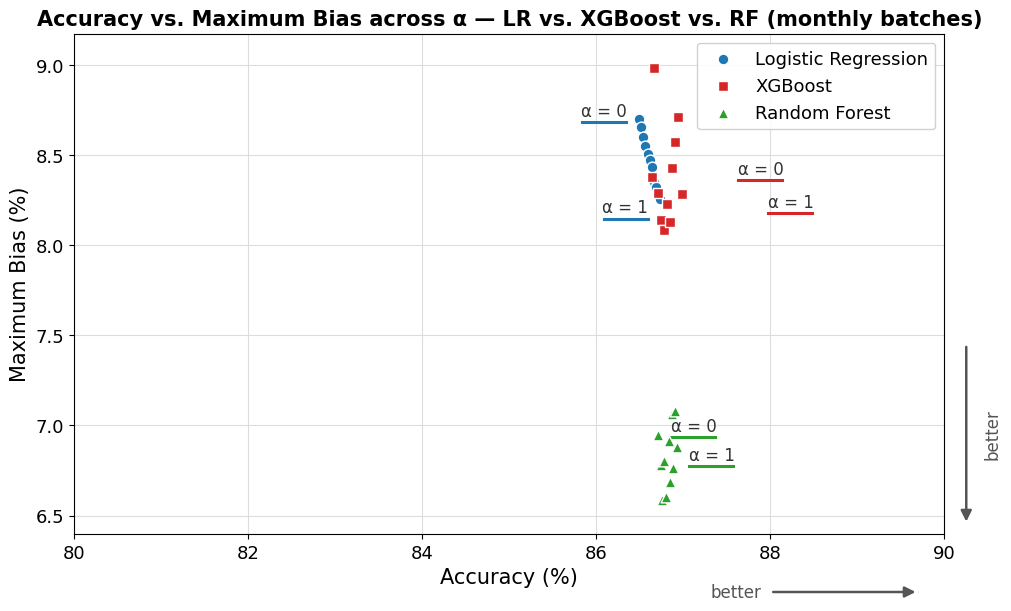

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_weekly.png


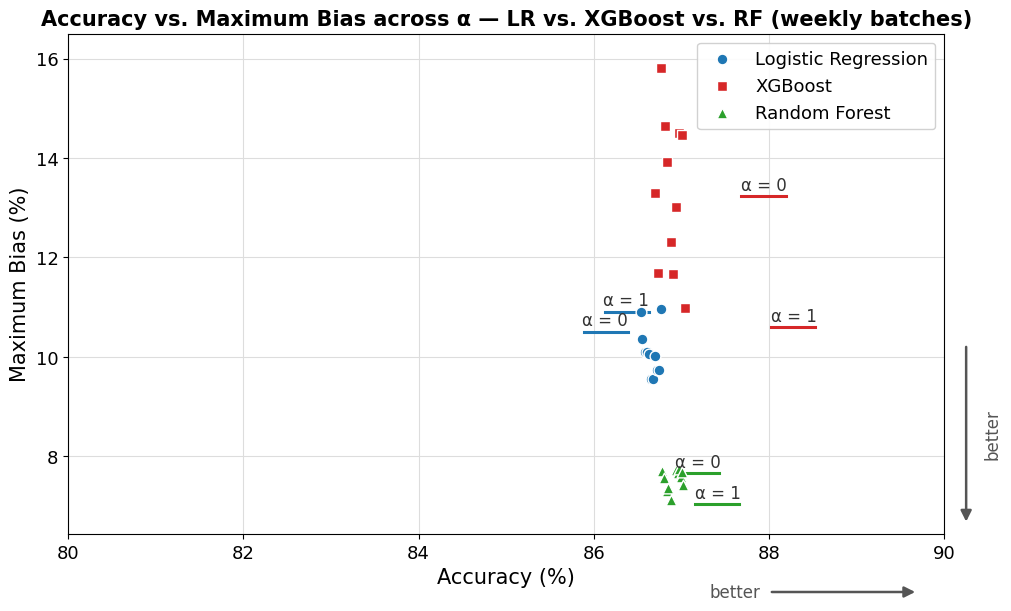

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_monthly_weekly.png


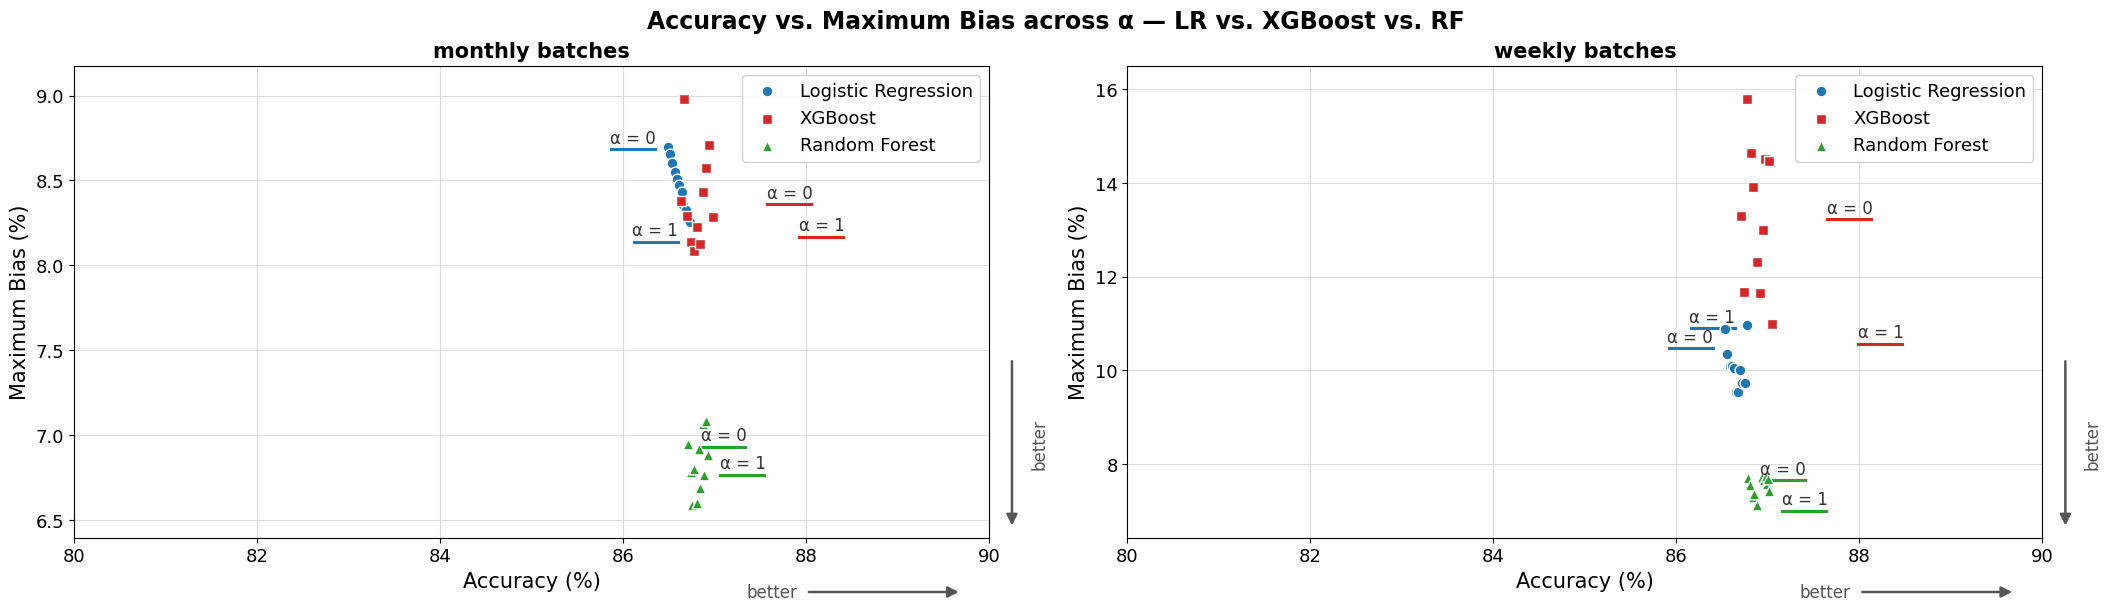

In [20]:
plot_frontier('monthly', 'Maximum Bias', temporal_frontier_points)
plot_frontier('weekly', 'Maximum Bias', temporal_frontier_points)
plot_frontier_pair('Maximum Bias', temporal_frontier_points)

### Temporal Stability

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_temporal_stability_monthly.png


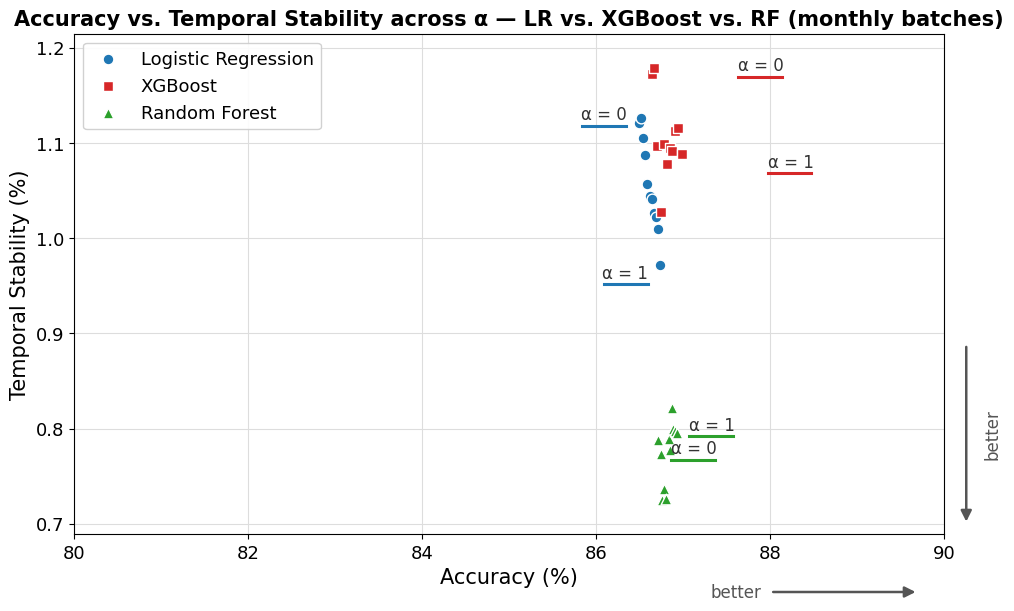

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_temporal_stability_weekly.png


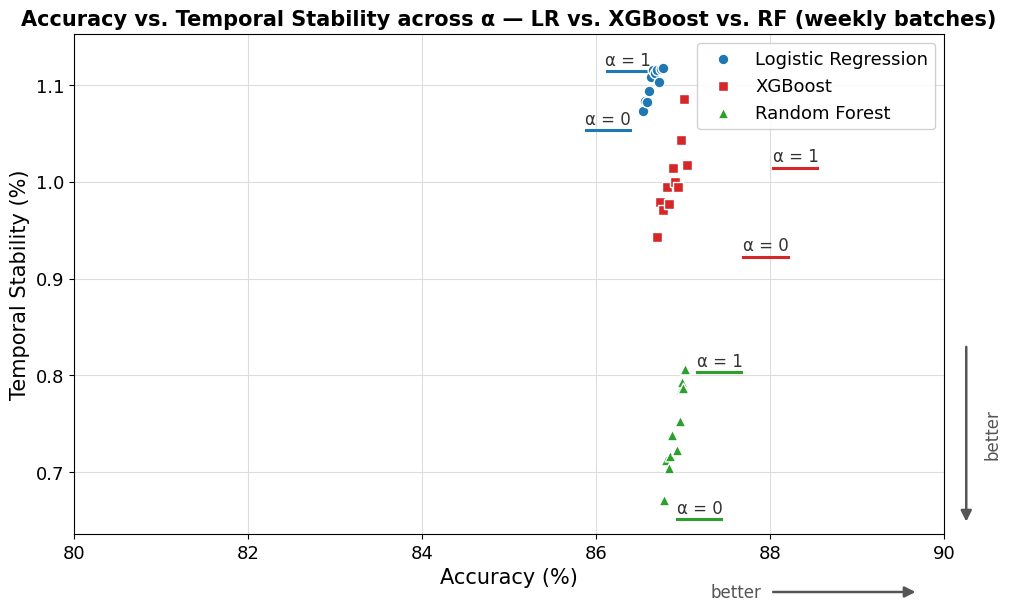

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_temporal_stability_monthly_weekly.png


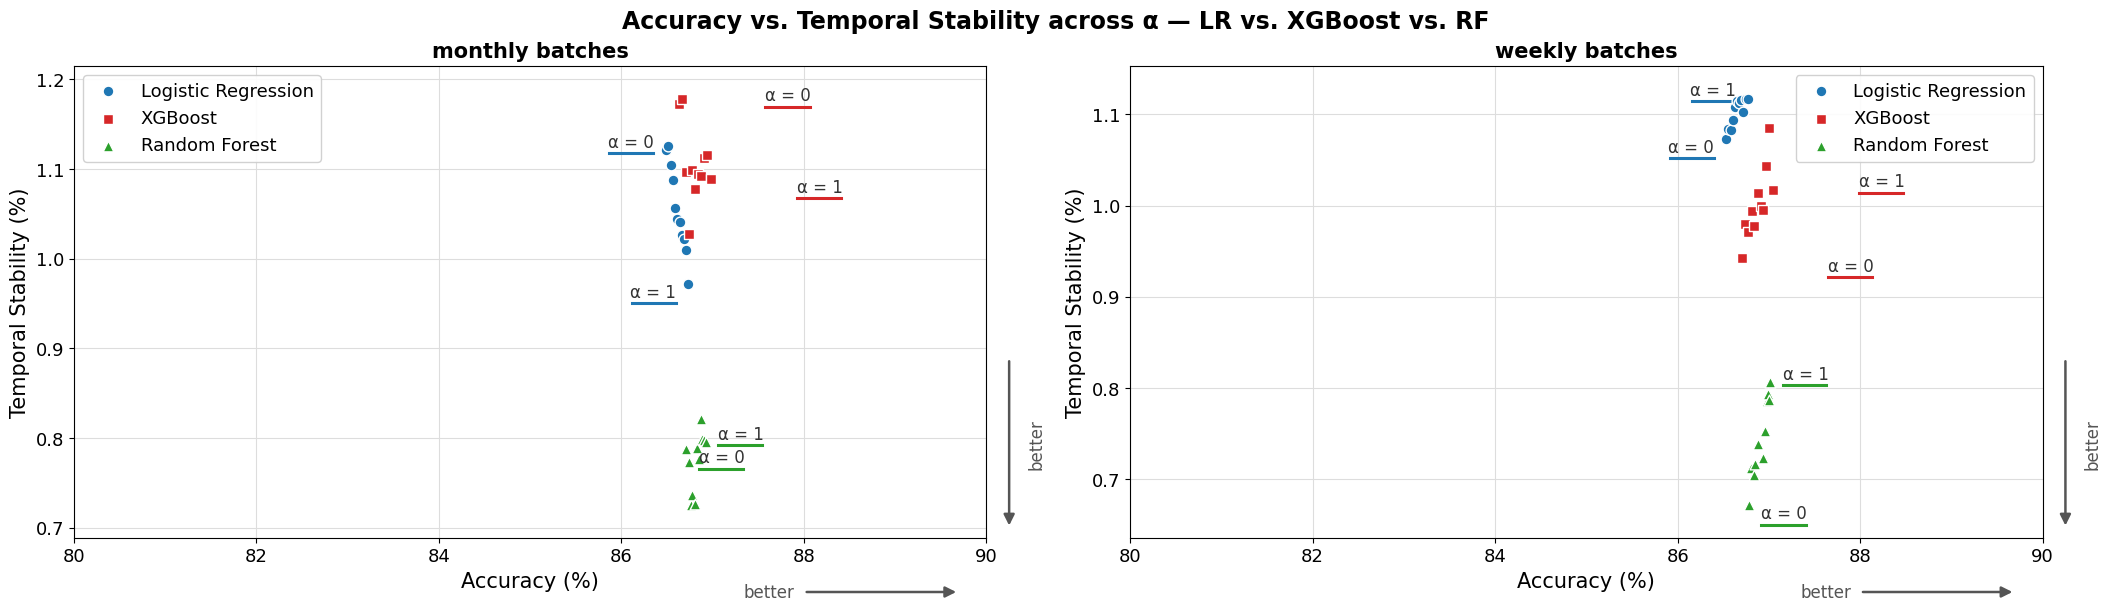

In [21]:
plot_frontier('monthly', 'Temporal Stability', temporal_frontier_points)
plot_frontier('weekly', 'Temporal Stability', temporal_frontier_points)
plot_frontier_pair('Temporal Stability', temporal_frontier_points)

### Maximum Bias Difference

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_difference_monthly.png


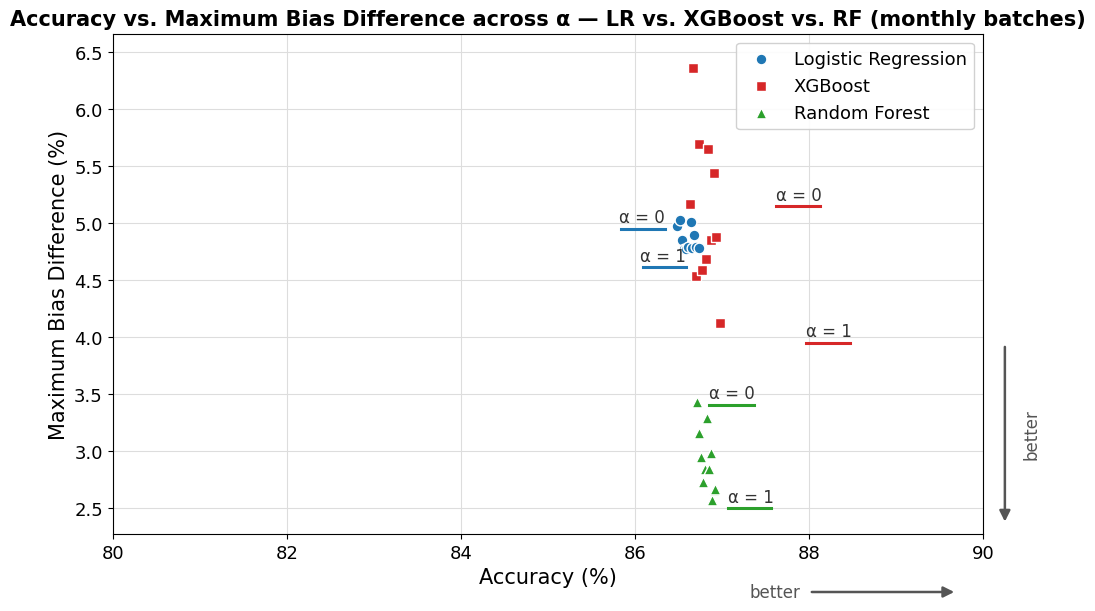

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_difference_weekly.png


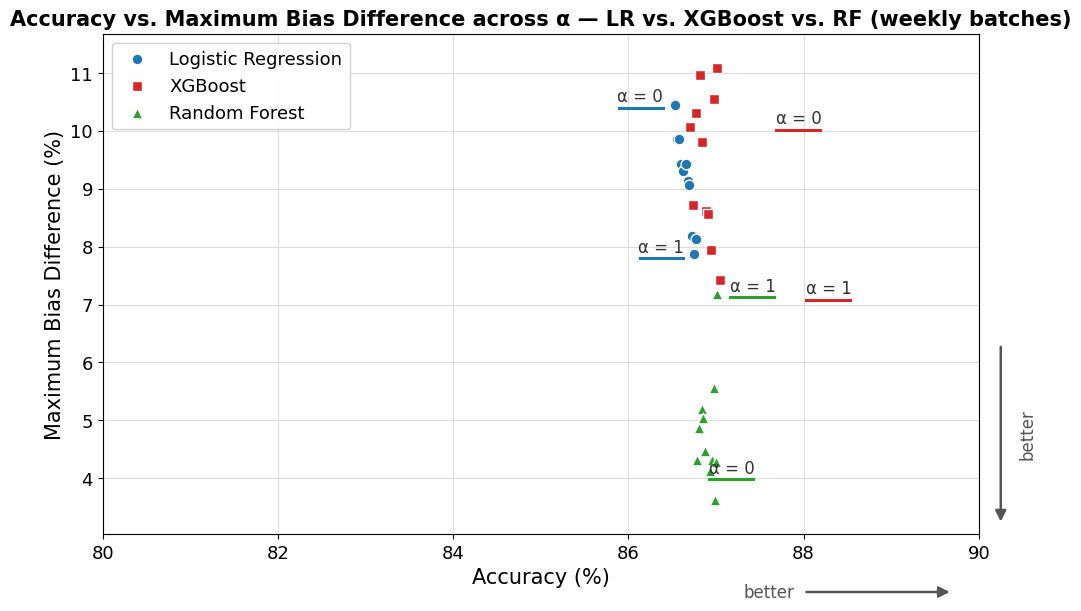

Figura salva em C:\master-degree-fairness-distribution_shifts\src\notebooks\figures\comparacao_baselines\fronteira_acc_maximum_bias_difference_monthly_weekly.png


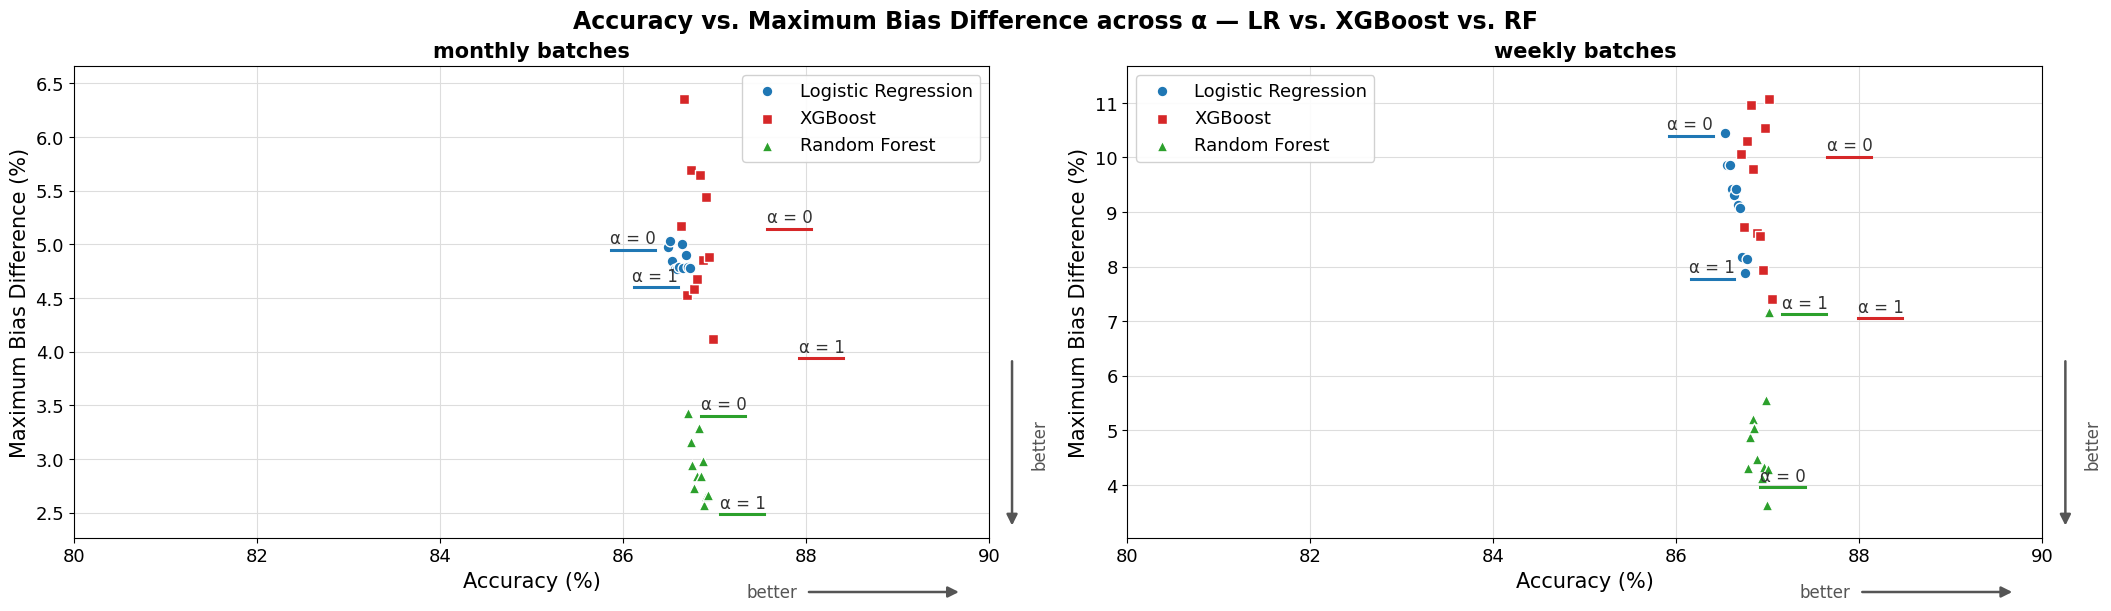

In [22]:
plot_frontier('monthly', 'Maximum Bias Difference', temporal_frontier_points)
plot_frontier('weekly', 'Maximum Bias Difference', temporal_frontier_points)
plot_frontier_pair('Maximum Bias Difference', temporal_frontier_points)